In [24]:
# Cell 1 - Setup: Earth Engine login
import ee
import geemap
ee.Authenticate()
ee.Initialize(project='btp1-506512')

**Result:** Earth Engine is connected to the project `btp1-506512`. Nothing to interpret here; if this cell fails, the login has expired and has to be done again.

In [25]:
# Cell 2 - Study area: Hamirpur + south Kangra, Himachal Pradesh
# (box moved 0.15 deg north of Hamirpur district, where many more landslides are mapped)
STUDY_AREA_COORDS = [76.28, 31.55, 76.75, 32.03]
AOI = ee.Geometry.Rectangle(STUDY_AREA_COORDS)

# UTM zone 43N, so slope and distances come out in metres
EPSG_CODE = 'EPSG:32643'
print("AOI defined")

AOI defined


**Result:** the study area is 76.28-76.75°E, 31.55-32.03°N (about 2,360 km²): almost all of Hamirpur plus parts of Kangra, Mandi, Una and Bilaspur. Everything after this is calculated in UTM 43N, so slopes and distances are real ground values.

In [26]:
# Cell 3 - Cloud and cloud-shadow masks for Landsat and Sentinel-2
# Landsat Collection 2: QA_PIXEL bit 3 = cloud, bit 4 = shadow (snow is kept)
def mask_landsat_sr(image):
    qa = image.select('QA_PIXEL')
    cloud_bit = 1 << 3
    shadow_bit = 1 << 4
    mask = qa.bitwiseAnd(cloud_bit).eq(0).And(qa.bitwiseAnd(shadow_bit).eq(0))
    optical = image.select('SR_B.').multiply(0.0000275).add(-0.2)
    return optical.updateMask(mask).copyProperties(image, ['system:time_start'])

# Sentinel-2: keep SCL classes 4 (vegetation), 5 (bare soil), 6 (water) and 11 (snow)
def mask_sentinel2_scl(image):
    scl = image.select('SCL')
    valid = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(11))
    return image.updateMask(valid).divide(10000).copyProperties(image, ['system:time_start'])

print("Cloud masks defined")

Cloud masks defined


**Result:** only the two mask functions are defined here. The Landsat mask removes cloud and shadow pixels; the Sentinel-2 mask keeps only clear land, water and snow pixels.

In [27]:
# Cell 4 - Median composites: ~2006 (Landsat 5/7, 2005-08), ~2016 (Sentinel-2, 2015-17), ~2024 (Sentinel-2, 2022-24)
# Sentinel-2 surface reflectance starts in 2017 over India, so ~2016 is effectively 2017
def get_landsat_composite(year_start, year_end, label):
    d_start = f'{year_start}-01-01'
    d_end = f'{year_end}-12-31'
    bands_57 = (['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5'], ['blue', 'green', 'red', 'nir', 'swir1'])
    bands_8 = (['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6'], ['blue', 'green', 'red', 'nir', 'swir1'])

    def load(collection_id, bands):
        return (ee.ImageCollection(collection_id)
                .filterBounds(AOI).filterDate(d_start, d_end)
                .filter(ee.Filter.lt('CLOUD_COVER', 30))
                .map(mask_landsat_sr)
                .select(*bands))

    merged = (load('LANDSAT/LT05/C02/T1_L2', bands_57)
              .merge(load('LANDSAT/LE07/C02/T1_L2', bands_57))
              .merge(load('LANDSAT/LC08/C02/T1_L2', bands_8)))
    print(f"[{label}] scenes found: {merged.size().getInfo()}")
    return merged.median().clip(AOI)

def get_sentinel2_composite(year_start, year_end, label):
    d_start = f'{year_start}-01-01'
    d_end = f'{year_end}-12-31'
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(AOI).filterDate(d_start, d_end)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
          .map(mask_sentinel2_scl)
          .select(['B2', 'B3', 'B4', 'B8', 'B11'],
                  ['blue', 'green', 'red', 'nir', 'swir1']))
    print(f"[{label}] scenes found: {s2.size().getInfo()}")
    return s2.median().clip(AOI)

img_2006 = get_landsat_composite(2005, 2008, 'Epoch1 ~2006')
img_2016 = get_sentinel2_composite(2015, 2017, 'Epoch2 ~2016')
img_2024 = get_sentinel2_composite(2022, 2024, 'Epoch3 ~2024')

[Epoch1 ~2006] scenes found: 102
[Epoch2 ~2016] scenes found: 79
[Epoch3 ~2024] scenes found: 415


**Result:** 102 scenes for ~2006, 79 for ~2016 and 415 for ~2024. Each composite is the median of all the cloud-masked scenes in its period, so every period has enough images for a clean, cloud-free picture. ~2016 has the fewest because Sentinel-2 surface reflectance only starts in 2017 here.

In [28]:
# Cell 5 - NDVI, NDWI and NDBI for each period
def add_indices(img, label=''):
    ndvi = img.normalizedDifference(['nir', 'red']).rename('ndvi')
    ndwi = img.normalizedDifference(['green', 'nir']).rename('ndwi')
    result = img.addBands([ndvi, ndwi])

    if 'swir1' in img.bandNames().getInfo():
        ndbi = img.normalizedDifference(['swir1', 'nir']).rename('ndbi')
        result = result.addBands(ndbi)

    print(f"[{label}] bands: {result.bandNames().getInfo()}")
    return result

img_2006 = add_indices(img_2006, '2006')
img_2016 = add_indices(img_2016, '2016')
img_2024 = add_indices(img_2024, '2024')

[2006] bands: ['blue', 'green', 'red', 'nir', 'swir1', 'ndvi', 'ndwi', 'ndbi']
[2016] bands: ['blue', 'green', 'red', 'nir', 'swir1', 'ndvi', 'ndwi', 'ndbi']
[2024] bands: ['blue', 'green', 'red', 'nir', 'swir1', 'ndvi', 'ndwi', 'ndbi']


**Result:** each period now has five reflectance bands plus three indices. NDVI is high for dense vegetation, NDWI for water and wet surfaces, and NDBI for built-up and bare ground. These three are the only factors that change between the periods.

In [29]:
# Cell 6 - Terrain, hydrology, road and soil factors
# Coarse layers are computed on their own grid (.reproject) - much faster, and avoids timeouts later
dem = ee.Image('USGS/SRTMGL1_003').clip(AOI)
elevation = dem.rename('elevation')
slope = ee.Terrain.slope(dem).rename('slope')
aspect = ee.Terrain.aspect(dem).rename('aspect')

# curvature (Laplacian of the DEM)
kernel = ee.Kernel.laplacian8(normalize=False)
plan_curv = dem.convolve(kernel).rename('plan_curvature')

# wetness index (TWI) from MERIT Hydro
flow_acc = ee.Image('MERIT/Hydro/v1_0_1').select('upa')
merit_proj = flow_acc.projection()
merit_scale = merit_proj.nominalScale()
slope_rad = slope.multiply(3.14159265 / 180)
twi = flow_acc.divide(slope_rad.tan().max(0.001)).log().rename('twi').clip(AOI)

# streams = upstream area > 25 km2
STREAM_THRESHOLD_KM2 = 25
stream_mask = flow_acc.gt(STREAM_THRESHOLD_KM2)

# distance to the nearest stream, in metres
distance_to_river = (
    stream_mask.fastDistanceTransform(256, 'pixels', 'squared_euclidean')
    .sqrt()
    .reproject(merit_proj)
    .multiply(merit_scale)
    .rename('distance_to_river')
    .clip(AOI)
)

# drainage density: share of stream pixels within 1 km
density_kernel = ee.Kernel.circle(radius=1000, units='meters')
drainage_density = (
    stream_mask.convolve(density_kernel)
    .reproject(merit_proj)
    .rename('drainage_density')
    .clip(AOI)
)

# distance to the nearest GRIP4 road
try:
  roads_me_ca = ee.FeatureCollection(
      'projects/sat-io/open-datasets/GRIP4/Middle-East-Central-Asia'
  )
  roads_sea = ee.FeatureCollection(
      'projects/sat-io/open-datasets/GRIP4/South-East-Asia'
  )
  roads_aoi = roads_me_ca.merge(roads_sea).filterBounds(AOI.buffer(5000))
  distance_to_road = (
      roads_aoi.distance(searchRadius=5000, maxError=100)
      .unmask(5000)  # more than 5 km from any road -> 5000
      .rename('distance_to_road')
      .clip(AOI)
  )
  print('GRIP4 road segments found near AOI:', roads_aoi.size().getInfo())
except Exception as e:
  print('Road network calculation note:', e)
  distance_to_road = (
      ee.Image.constant(5000).rename('distance_to_road').clip(AOI)
  )

# soil clay content (OpenLandMap)
soil_clay = (
    ee.Image('OpenLandMap/SOL/SOL_CLAY-WFRACTION_USDA-3A1A1A_M/v02')
    .select('b0')
    .rename('soil_clay')
    .clip(AOI)
)

terrain_stack = (
    elevation.addBands(slope)
    .addBands(aspect)
    .addBands(plan_curv)
    .addBands(twi)
    .addBands(drainage_density)
    .addBands(distance_to_river)
    .addBands(distance_to_road)
    .addBands(soil_clay)
)

print('Conditioning factor bands:', terrain_stack.bandNames().getInfo())

GRIP4 road segments found near AOI: 131
Conditioning factor bands: ['elevation', 'slope', 'aspect', 'plan_curvature', 'twi', 'drainage_density', 'distance_to_river', 'distance_to_road', 'soil_clay']


**Result:** 131 GRIP4 road segments were found around the study area, and the nine terrain, hydrology, road and soil bands are ready. These do not change over time, so the same layers are used for all three periods. Distance to road is capped at 5 km.

In [30]:
# Cell 7 - Mean annual rainfall from CHIRPS, 2009-2025
# CHIRPS values before 2009 are unrealistically low over this area, so they are left out
RAIN_START, RAIN_END = 2009, 2025
chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/PENTAD').filterDate(f'{RAIN_START}-01-01',
                                                                 f'{RAIN_END}-12-31')
chirps_proj = chirps.first().projection()
mean_annual_rain = (chirps.filterBounds(AOI)
                      .sum()
                      .divide(RAIN_END - RAIN_START + 1)
                      .reproject(chirps_proj)
                      .rename('mean_annual_rainfall_mm')
                      .clip(AOI))
print(f'Rainfall layer ready (CHIRPS mean annual total, {RAIN_START}-{RAIN_END})')

Rainfall layer ready (CHIRPS mean annual total, 2009-2025)


**Result:** the rainfall layer is the average yearly CHIRPS total for 2009-2025, about 1,860 mm over the study area. The earlier years are left out because CHIRPS gives only about 466 mm a year for 2001-2008 here, which is not realistic for these hills.

In [31]:
# Cell 8 - Stack all 13 factors into one image per period
def build_feature_stack(optical_img, terrain, rainfall):
    return (optical_img.select(['ndvi','ndwi','ndbi'])
                       .addBands(terrain)
                       .addBands(rainfall))

stack_2006 = build_feature_stack(img_2006, terrain_stack, mean_annual_rain)
stack_2016 = build_feature_stack(img_2016, terrain_stack, mean_annual_rain)
stack_2024 = build_feature_stack(img_2024, terrain_stack, mean_annual_rain)

FEATURE_BANDS = [
    'ndvi', 'ndwi', 'ndbi',
    'elevation', 'slope', 'aspect', 'plan_curvature', 'twi',
    'drainage_density', 'distance_to_river', 'distance_to_road',
    'soil_clay', 'mean_annual_rainfall_mm'
]
print(f'Feature stack ready ({len(FEATURE_BANDS)} bands): {FEATURE_BANDS}')

Feature stack ready (13 bands): ['ndvi', 'ndwi', 'ndbi', 'elevation', 'slope', 'aspect', 'plan_curvature', 'twi', 'drainage_density', 'distance_to_river', 'distance_to_road', 'soil_clay', 'mean_annual_rainfall_mm']


**Result:** each period now has one 13-band image (3 indices + 10 other factors). These stacks are what the models read their values from.

In [32]:
# Cell 9 - Interactive map of all layers (tick a layer in the menu to show it)
Map = geemap.Map()
Map.centerObject(AOI, 10)
Map.add_basemap('SATELLITE')

# display settings
rgb_vis    = {'min': 0.0,  'max': 0.3,  'bands': ['red', 'green', 'blue']}
ndvi_vis   = {'min': -0.2, 'max': 0.8,  'palette': ['red', 'yellow', 'green']}
slope_vis  = {'min': 0,    'max': 70,   'palette': ['white', 'orange', 'red', 'darkred']}
change_vis = {'min': -0.5, 'max': 0.5,  'palette': ['red', 'white', 'green']}
rain_vis   = {'min': 300,  'max': 1000, 'palette': ['white', 'cyan', 'blue']}
river_vis  = {'min': 0,    'max': 4000, 'palette': ['blue', 'cyan', 'white']}
road_vis   = {'min': 0,    'max': 5000, 'palette': ['red', 'orange', 'white']}
clay_vis   = {'min': 0,    'max': 40,   'palette': ['khaki', 'peru', 'saddlebrown']}
twi_vis    = {'min': -5,   'max': 15,   'palette': ['white', 'lightblue', 'blue', 'darkblue']}
elev_vis   = {'min': 400,  'max': 2500, 'palette': ['green', 'yellow', 'orange', 'white']}

# satellite composites
Map.addLayer(img_2006.select(['red', 'green', 'blue']), rgb_vis,  'True Color 2006',        False)
Map.addLayer(img_2016.select(['red', 'green', 'blue']), rgb_vis,  'True Color 2016',        False)
Map.addLayer(img_2024.select(['red', 'green', 'blue']), rgb_vis,  'True Color 2024',        True)

# spectral indices
Map.addLayer(img_2006.select('ndvi'), ndvi_vis, 'NDVI 2006',            False)
Map.addLayer(img_2016.select('ndvi'), ndvi_vis, 'NDVI 2016',            False)
Map.addLayer(img_2024.select('ndvi'), ndvi_vis, 'NDVI 2024',            False)

ndvi_change = img_2024.select('ndvi').subtract(img_2006.select('ndvi'))
Map.addLayer(ndvi_change, change_vis, 'NDVI Change 2006 to 2024',       False)

# terrain
Map.addLayer(elevation,    elev_vis,  'Elevation (m)',                  False)
Map.addLayer(slope,        slope_vis, 'Slope (degrees)',                False)
Map.addLayer(twi,          twi_vis,   'Topographic Wetness Index',      False)
Map.addLayer(plan_curv,    {'min': -50, 'max': 50, 'palette': ['blue','white','red']}, 'Plan Curvature', False)

# hydrology
Map.addLayer(drainage_density, {'min': 0, 'max': 0.3, 'palette': ['white','cyan','blue']}, 'Drainage Density (stream share in 1 km)', False)
Map.addLayer(distance_to_river, river_vis, 'Distance to River (m)',     False)

# roads and soil
Map.addLayer(distance_to_road, road_vis,  'Distance to Road (m)',       False)
Map.addLayer(soil_clay,        clay_vis,  'Soil Clay Content (%)',      False)

# rainfall
Map.addLayer(mean_annual_rain, rain_vis,  'Mean Annual Rainfall (mm)',  False)

# study area boundary
aoi_outline = ee.Image().byte().paint(
    featureCollection=ee.FeatureCollection([ee.Feature(AOI)]),
    color=1,
    width=3
)
Map.addLayer(aoi_outline, {'palette': ['FF0000']}, 'Study Area Boundary', True)

Map.addLayerControl()
Map

Map(center=[31.790008098520335, 76.5150000000011], controls=(WidgetControl(options=['position', 'transparent_b…

**Result:** an interactive map for checking the layers. Worth looking at: the slope layer (steep ridges vs the flat terraces along the Beas), the 2024 true-colour image, and the road and river distance layers. It is only for checking; nothing is saved.

In [33]:
# Cell 10 - Landslide points from the Bhuvan inventory (2014, 2017, 2023) + non-landslide points
import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

INVENTORY_CSV = "Bhuvan_inventory/bhuvan_HP_landslides_2014_2017_2023.csv"
PIXEL_M = 30  # pixel size used to merge duplicate landslides
MIN_GAP_M = 500  # non-landslide points at least 0.5 km from any landslide
MAX_GAP_M = 3000  # ...and within 3 km of one, i.e. inside the area Bhuvan mapped
NEG_RATIO = 1.0  # one non-landslide point per landslide
EARTH_R = 6371000.0

minlon, minlat, maxlon, maxlat = STUDY_AREA_COORDS

# landslide points
inv = pd.read_csv(INVENTORY_CSV)
pos = inv[(inv.lon >= minlon) & (inv.lon <= maxlon) &
          (inv.lat >= minlat) & (inv.lat <= maxlat)].copy()
print(f"Bhuvan polygons inside AOI: {len(pos)}")
print(pos.groupby('year').size().to_string())

# merge landslides in the same 30 m pixel (avoids the same sample in train and test)
dlat = PIXEL_M / 111320.0
dlon = PIXEL_M / (111320.0 * np.cos(np.radians((minlat + maxlat) / 2)))
pos['px'] = (pos.lon // dlon).astype(int).astype(str) + '_' + (pos.lat // dlat).astype(int).astype(str)
pos = pos.sort_values('year').drop_duplicates('px', keep='first')  # keep the earliest season
print(f"After merging same-pixel duplicates: {len(pos)}")

df_positive = pd.DataFrame({
    'name': [f"BHUVAN_{y}_{i}" for i, y in enumerate(pos.year)],
    'lon': pos.lon.round(6).values,
    'lat': pos.lat.round(6).values,
    'source': 'Bhuvan_SLIM_' + pos.year.astype(str).values,
    'label': 1,
    'season': pos.year.values,
})

# non-landslide points
rng = np.random.default_rng(42)
tree = BallTree(np.radians(df_positive[['lat', 'lon']].values), metric='haversine')
n_needed = int(len(df_positive) * NEG_RATIO)

neg_lon, neg_lat = [], []
while len(neg_lon) < n_needed:
    lon = rng.uniform(minlon, maxlon, 20000)
    lat = rng.uniform(minlat, maxlat, 20000)
    d, _ = tree.query(np.radians(np.c_[lat, lon]), k=1)
    d = d[:, 0] * EARTH_R
    ok = (d > MIN_GAP_M) & (d < MAX_GAP_M)
    neg_lon.extend(lon[ok]); neg_lat.extend(lat[ok])
neg_lon, neg_lat = np.array(neg_lon[:n_needed]), np.array(neg_lat[:n_needed])

# give each non-landslide point a season in the same proportion as the landslides
season_share = df_positive.season.value_counts(normalize=True)
neg_season = rng.choice(season_share.index.values, size=n_needed, p=season_share.values)

df_negative = pd.DataFrame({
    'name': [f"NON_LS_{i}" for i in range(n_needed)],
    'lon': neg_lon.round(6), 'lat': neg_lat.round(6),
    'source': 'Random_Stable_Zone', 'label': 0, 'season': neg_season,
})

df_inventory = pd.concat([df_positive, df_negative], ignore_index=True)
SAMPLED_CACHE = {}  # new points, so Cell 11 samples from scratch
df_inventory.to_csv("Bhuvan_inventory/inventory_samples_AOI.csv", index=False)

print(f"\nPositives: {len(df_positive)}  |  Negatives: {len(df_negative)}  |  Total: {len(df_inventory)}")
print(pd.crosstab(df_inventory.season, df_inventory.label).to_string())
display(df_inventory.sample(10, random_state=1))

Bhuvan polygons inside AOI: 4431
year
2014     698
2017      39
2023    3694
After merging same-pixel duplicates: 4353

Positives: 4353  |  Negatives: 4353  |  Total: 8706
label      0     1
season            
2014     689   695
2017      34    38
2023    3630  3620


,name,lon,lat,source,label,season
1600,BHUVAN_2023_1600,76.476323,31.934243,Bhuvan_SLIM_2023,1,2023
1829,BHUVAN_2023_1829,76.579603,31.771646,Bhuvan_SLIM_2023,1,2023
2567,BHUVAN_2023_2567,76.569506,31.815482,Bhuvan_SLIM_2023,1,2023
311,BHUVAN_2014_311,76.663418,31.838512,Bhuvan_SLIM_2014,1,2014
1933,BHUVAN_2023_1933,76.619987,31.788403,Bhuvan_SLIM_2023,1,2023
8432,NON_LS_4079,76.665291,31.872388,Random_Stable_Zone,0,2023
2385,BHUVAN_2023_2385,76.511526,31.805879,Bhuvan_SLIM_2023,1,2023
5755,NON_LS_1402,76.517808,31.845990,Random_Stable_Zone,0,2014
397,BHUVAN_2014_397,76.644169,31.731763,Bhuvan_SLIM_2014,1,2014
4697,NON_LS_344,76.350206,31.625760,Random_Stable_Zone,0,2023


**Result:**
- 4,431 Bhuvan landslides fall inside the box (698 in 2014, 39 in 2017, 3,694 in 2023).
- After merging the ones in the same 30 m pixel, 4,353 landslide points remain.
- 4,353 non-landslide points are added 0.5-3 km away from them, giving 8,706 points in total.
- The non-landslide points get seasons in the same proportion as the landslides, so each season is roughly balanced (e.g. 2023: 3,620 landslides vs 3,630 non-landslides).

In [34]:
# Cell 11 - Read the factor values at every point (the ML dataset)
# Each point uses imagery from before its season: 2014 -> stack_2006, 2017 and 2023 -> stack_2016
# Runs in batches with a cache, so if it stops just run it again
import time
import pandas as pd

STACK_FOR_SEASON = {2014: stack_2006, 2017: stack_2016, 2023: stack_2016}
BATCH = 1000
MIN_BATCH = 100

if 'SAMPLED_CACHE' not in globals():
    SAMPLED_CACHE = {}

def sample_points(df_part, stack):
    feats = [ee.Feature(ee.Geometry.Point([r.lon, r.lat]),
                        {'point_id': int(i), 'label': int(r.label),
                         'season': int(r.season), 'source': str(r.source)})
             for i, r in df_part.iterrows()]
    out = stack.sampleRegions(collection=ee.FeatureCollection(feats),
                              properties=['point_id', 'label', 'season', 'source'],
                              scale=30, geometries=False, tileScale=16)
    return [f['properties'] for f in out.getInfo()['features']]

def sample_with_retry(df_part, stack, key):
    if key in SAMPLED_CACHE:
        return
    try:
        SAMPLED_CACHE[key] = sample_points(df_part, stack)
    except ee.EEException as e:
        if len(df_part) <= MIN_BATCH:
            raise
        print(f"   batch {key}: {str(e)[:60]} -> splitting into two halves")
        half = len(df_part) // 2
        sample_with_retry(df_part.iloc[:half], stack, key + ('a',))
        sample_with_retry(df_part.iloc[half:], stack, key + ('b',))
        SAMPLED_CACHE[key] = SAMPLED_CACHE.pop(key + ('a',)) + SAMPLED_CACHE.pop(key + ('b',))

t0 = time.time()
for season, stack in STACK_FOR_SEASON.items():
    part = df_inventory[df_inventory.season == season]
    for start in range(0, len(part), BATCH):
        sample_with_retry(part.iloc[start:start + BATCH], stack, (season, start))
        print(f"[{(time.time() - t0) / 60:5.1f} min] season {season}: "
              f"sampled {min(start + BATCH, len(part))}/{len(part)}")

rows = [r for batch in SAMPLED_CACHE.values() for r in batch]
df_ml = pd.DataFrame(rows).drop_duplicates('point_id')
# add lon/lat back (needed for the spatial blocks)
df_ml = df_ml.merge(df_inventory[['lon', 'lat']], left_on='point_id', right_index=True)

print(f'\nExtraction complete! Dataset shape: {df_ml.shape}')
print(f'Points dropped (fell on masked/no-data pixels): {len(df_inventory) - len(df_ml)}')
print(pd.crosstab(df_ml.season, df_ml.label).to_string())

features_present = [c for c in FEATURE_BANDS if c in df_ml.columns]
print(f'\nFeatures extracted ({len(features_present)}/{len(FEATURE_BANDS)}): {features_present}')
missing = df_ml[features_present].isna().sum()
print('Missing values per feature:', missing[missing > 0].to_dict() or 'none')
df_ml.to_csv("Bhuvan_inventory/ml_dataset_AOI.csv", index=False)
display(df_ml.head(10))

[  1.1 min] season 2014: sampled 1000/1384
[  1.9 min] season 2014: sampled 1384/1384
[  2.0 min] season 2017: sampled 72/72
[  2.5 min] season 2023: sampled 1000/7250
[  3.0 min] season 2023: sampled 2000/7250
[  3.9 min] season 2023: sampled 3000/7250
[  4.2 min] season 2023: sampled 4000/7250
[  4.9 min] season 2023: sampled 5000/7250
[  5.5 min] season 2023: sampled 6000/7250
[  6.2 min] season 2023: sampled 7000/7250
[  6.4 min] season 2023: sampled 7250/7250

Extraction complete! Dataset shape: (8696, 19)
Points dropped (fell on masked/no-data pixels): 10
label      0     1
season            
2014     686   695
2017      33    38
2023    3624  3620

Features extracted (13/13): ['ndvi', 'ndwi', 'ndbi', 'elevation', 'slope', 'aspect', 'plan_curvature', 'twi', 'drainage_density', 'distance_to_river', 'distance_to_road', 'soil_clay', 'mean_annual_rainfall_mm']
Missing values per feature: none


,aspect,distance_to_river,distance_to_road,drainage_density,elevation,label,mean_annual_rainfall_mm,ndbi,ndvi,ndwi,plan_curvature,point_id,season,slope,soil_clay,source,twi,lon,lat
0,180.000000,1237.656042,565.532723,0.000000,870,1,1735.950270,-0.230097,0.677151,-0.640794,-22,0,2014,19.602388,28,Bhuvan_SLIM_2014,-3.890178,76.749848,31.865390
1,166.748871,1173.410463,505.127186,0.000000,839,1,1735.950270,-0.306153,0.766875,-0.723591,41,1,2014,22.575787,28,Bhuvan_SLIM_2014,-4.044989,76.749541,31.864937
2,211.404190,787.147668,135.978157,0.049315,652,1,1735.950270,-0.255829,0.703839,-0.662807,2,2,2014,27.116238,31,Bhuvan_SLIM_2014,-2.867036,76.748481,31.861103
3,163.104385,1117.053481,4.469360,0.000000,818,1,1736.373301,-0.030194,0.440347,-0.494302,-42,3,2014,27.675154,29,Bhuvan_SLIM_2014,-4.276862,76.747579,31.829060
4,116.201294,207.431624,63.880921,0.060274,689,1,1746.673621,-0.133150,0.614199,-0.578133,12,4,2014,21.963999,27,Bhuvan_SLIM_2014,-4.013760,76.746166,31.791356
5,195.769928,1117.053481,518.741495,0.000000,885,1,1736.373301,0.005212,0.429645,-0.489904,-2,5,2014,22.807844,28,Bhuvan_SLIM_2014,-4.055735,76.744645,31.805299
6,202.553101,1248.042149,557.860195,0.000000,859,1,1736.373301,-0.048149,0.471676,-0.512268,13,6,2014,16.593019,26,Bhuvan_SLIM_2014,-3.018120,76.743535,31.805159
7,203.437439,1311.912780,564.899886,0.000000,848,1,1736.373301,-0.066120,0.484701,-0.505378,12,7,2014,18.532463,26,Bhuvan_SLIM_2014,-3.135896,76.742859,31.805110
8,205.609268,593.993775,464.914767,0.030137,754,1,1746.673621,-0.181590,0.677180,-0.624225,-3,8,2014,25.858721,26,Bhuvan_SLIM_2014,-4.197588,76.741147,31.791281
9,189.280258,540.915496,419.603233,0.041096,711,1,1746.673621,-0.171576,0.669148,-0.620537,-11,9,2014,30.561361,28,Bhuvan_SLIM_2014,-3.701888,76.741014,31.790652


**Result:**
- The 13 factor values were read at 8,696 points; 10 non-landslide points fell on pixels with no data and were dropped.
- No missing values are left, so all points can be used for training.
- The table at the end is a quick look at the first rows (label 1 = landslide, 0 = non-landslide).
- The dataset is saved as `Bhuvan_inventory/ml_dataset_AOI.csv`.

Rows used: 8696 (dropped 0 with missing values)
Features (14): ['ndvi', 'ndwi', 'ndbi', 'elevation', 'slope', 'plan_curvature', 'twi', 'drainage_density', 'distance_to_river', 'distance_to_road', 'soil_clay', 'mean_annual_rainfall_mm', 'northness', 'eastness']

A  kNN            done
A  SVM            done
A  ANN            done
A  Random Forest  done
A  XGBoost        done
B  kNN            done
B  SVM            done
B  ANN            done
B  Random Forest  done
B  XGBoost        done
C  kNN            done
C  SVM            done
C  ANN            done
C  Random Forest  done
C  XGBoost        done

ROC-AUC by test:
Test           A: random 70/30  B: spatial 5 km blocks  C: train 2014 -> test 2023
Model                                                                             
ANN                      0.924                   0.901                       0.767
Random Forest            0.932                   0.875                       0.813
SVM                      0.933             

,Model,Test,OA,Kappa,F1,ROC_AUC
0,kNN,A: random 70/30,0.843,0.686,0.849,0.921
1,SVM,A: random 70/30,0.860,0.721,0.860,0.933
2,ANN,A: random 70/30,0.849,0.699,0.850,0.924
3,Random Forest,A: random 70/30,0.856,0.713,0.857,0.932
4,XGBoost,A: random 70/30,0.907,0.814,0.908,0.967
5,kNN,B: spatial 5 km blocks,0.793,0.586,0.793,0.876
6,SVM,B: spatial 5 km blocks,0.811,0.622,0.811,0.886
7,ANN,B: spatial 5 km blocks,0.820,0.640,0.815,0.901
8,Random Forest,B: spatial 5 km blocks,0.785,0.570,0.775,0.875
9,XGBoost,B: spatial 5 km blocks,0.749,0.498,0.717,0.851


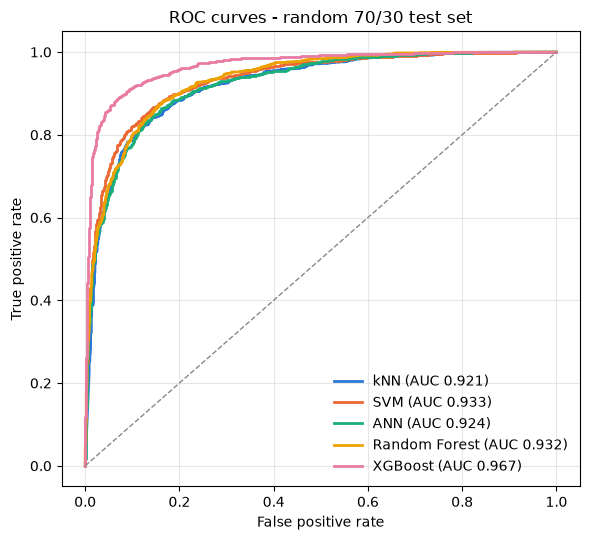

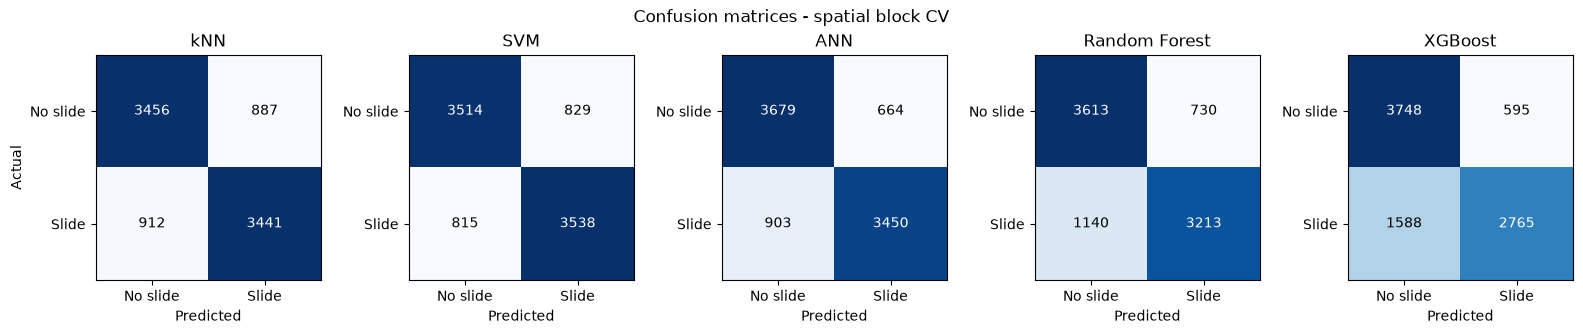

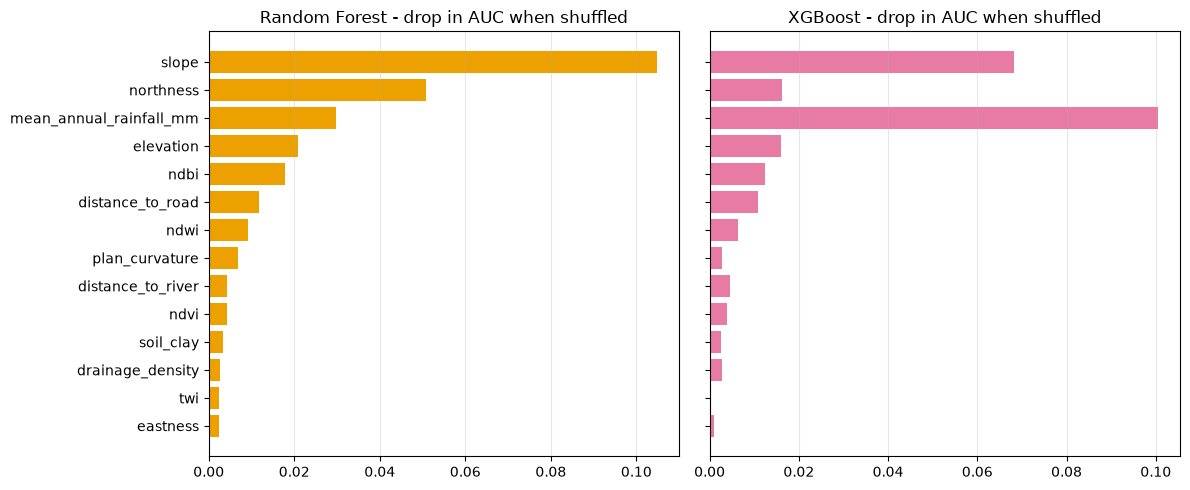

Saved to Results/: model_comparison.csv, roc_curves.png, confusion_matrices_spatial.png, factor_importance.png/.csv


In [35]:
# Cell 12 - Model comparison: kNN, SVM, ANN, Random Forest, XGBoost
# Three tests: A = random 70/30 split, B = spatial 5 km block CV, C = train 2014/2017, test 2023
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

RESULTS_DIR = Path("Results")
RESULTS_DIR.mkdir(exist_ok=True)
BLOCK_DEG = 0.05  # ~5 km blocks

# reload the saved dataset if the kernel was restarted
if 'df_ml' not in globals():
    df_ml = pd.read_csv("Bhuvan_inventory/ml_dataset_AOI.csv")

data = df_ml.copy()
# aspect is circular, so use northness (cos) and eastness (sin)
if 'aspect' in data.columns:
    rad = np.radians(data['aspect'])
    data['northness'] = np.cos(rad)
    data['eastness'] = np.sin(rad)
FEATURES = [c for c in FEATURE_BANDS if c in data.columns and c != 'aspect']
if 'aspect' in data.columns:
    FEATURES += ['northness', 'eastness']

n_before = len(data)
data = data.dropna(subset=FEATURES + ['label']).reset_index(drop=True)
print(f"Rows used: {len(data)} (dropped {n_before - len(data)} with missing values)")
print(f"Features ({len(FEATURES)}): {FEATURES}\n")

X = data[FEATURES].to_numpy()
y = data['label'].astype(int).to_numpy()

# scaling for kNN, SVM and ANN (trees do not need it)
MODELS = {
    'kNN': make_pipeline(StandardScaler(),
                         KNeighborsClassifier(n_neighbors=15, weights='distance')),
    # calibration gives the SVM probabilities (needed for ROC-AUC)
    'SVM': make_pipeline(StandardScaler(),
                         CalibratedClassifierCV(SVC(C=10, gamma='scale', random_state=42),
                                                ensemble=False)),
    'ANN': make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                       early_stopping=True, max_iter=500, random_state=42)),
    'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                            n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             eval_metric='logloss', n_jobs=-1, random_state=42),
}
COLORS = {'kNN': '#2a78d6', 'SVM': '#eb6834', 'ANN': '#1baf7a',
          'Random Forest': '#eda100', 'XGBoost': '#e87ba4'}

def score(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {'OA': accuracy_score(y_true, pred),
            'Kappa': cohen_kappa_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'ROC_AUC': roc_auc_score(y_true, prob)}

rows = []

# A) random 70/30
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
fitted, prob_A = {}, {}
for name, model in MODELS.items():
    fitted[name] = clone(model).fit(X_tr, y_tr)
    prob_A[name] = fitted[name].predict_proba(X_te)[:, 1]
    rows.append({'Model': name, 'Test': 'A: random 70/30', **score(y_te, prob_A[name])})
    print(f"A  {name:14s} done")

# B) spatial block CV
blocks = (np.floor(data['lon'] / BLOCK_DEG).astype(int).astype(str) + '_' +
          np.floor(data['lat'] / BLOCK_DEG).astype(int).astype(str)).to_numpy()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
prob_B = {}
for name, model in MODELS.items():
    prob_B[name] = cross_val_predict(clone(model), X, y, groups=blocks, cv=cv,
                                     method='predict_proba')[:, 1]
    rows.append({'Model': name, 'Test': 'B: spatial 5 km blocks', **score(y, prob_B[name])})
    print(f"B  {name:14s} done")

# C) temporal: 2014/2017 -> 2023
train_t = data['season'].isin([2014, 2017]).to_numpy()
test_t = (data['season'] == 2023).to_numpy()
for name, model in MODELS.items():
    m = clone(model).fit(X[train_t], y[train_t])
    rows.append({'Model': name, 'Test': 'C: train 2014 -> test 2023',
                 **score(y[test_t], m.predict_proba(X[test_t])[:, 1])})
    print(f"C  {name:14s} done")

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print("\nROC-AUC by test:")
print(results.pivot(index='Model', columns='Test', values='ROC_AUC').round(3).to_string())
print("\nFull table:")
display(results.round(3))

# figures: ROC curves (test A) and confusion matrices (test B)
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, p in prob_A.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, lw=2, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], ls='--', lw=1, color='#8a8984')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC curves - random 70/30 test set')
ax.legend(frameon=False, loc='lower right'); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "roc_curves.png", dpi=300); plt.show()

fig, axes = plt.subplots(1, len(MODELS), figsize=(3.2 * len(MODELS), 3.2))
for ax, (name, p) in zip(axes, prob_B.items()):
    cm = confusion_matrix(y, (p >= 0.5).astype(int))
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['No slide', 'Slide']); ax.set_yticks([0, 1], ['No slide', 'Slide'])
    ax.set_title(name); ax.set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
fig.suptitle('Confusion matrices - spatial block CV')
fig.tight_layout(); fig.savefig(RESULTS_DIR / "confusion_matrices_spatial.png", dpi=300); plt.show()

# permutation importance: drop in AUC when one factor is shuffled
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
imp_table = {}
for ax, name in zip(axes, ['Random Forest', 'XGBoost']):
    pi = permutation_importance(fitted[name], X_te, y_te, scoring='roc_auc',
                                n_repeats=5, random_state=42, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=FEATURES)
    imp_table[name] = imp
    order = imp_table['Random Forest'].sort_values().index
    ax.barh(order, imp[order], color=COLORS[name])
    ax.set_title(f'{name} - drop in AUC when shuffled'); ax.grid(axis='x', alpha=0.3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "factor_importance.png", dpi=300); plt.show()
pd.DataFrame(imp_table).sort_values('Random Forest', ascending=False).to_csv(
    RESULTS_DIR / "factor_importance.csv")
print("Saved to Results/: model_comparison.csv, roc_curves.png, "
      "confusion_matrices_spatial.png, factor_importance.png/.csv")

**Result:**
- **Test A (random split):** every model scores ROC-AUC above 0.92 and XGBoost is best (0.967).
- **Test B (spatial blocks):** all models drop and the ranking changes. ANN is best (0.901) and XGBoost is last (0.851). XGBoost loses the most (0.116), which means it partly memorises locations. Test B is the realistic number for mapping new areas.
- **Test C (2014/2017 → 2023):** 0.77-0.82. Lower, because 2023 was a much more extreme season and the older points use Landsat instead of Sentinel-2, but the models still have useful skill.
- **ROC curves:** the closer a curve hugs the top-left corner, the better; the diagonal line is a random guess.
- **Confusion matrices:** the diagonal boxes are correct predictions; the other two are false alarms (stable ground predicted as landslide) and missed landslides.
- **Factor importance:** slope, northness and rainfall give the biggest drop in AUC when shuffled, so the models rely on them most.

Training: 7391 points | Test (held out): 1305 points
kNN            tuned in  0.1 min | validation AUC 0.885 | {'n_neighbors': 52, 'p': 1, 'weights': 'distance'}
SVM            tuned in  0.4 min | validation AUC 0.900 | {'C': 1.30965, 'gamma': 0.02705}
ANN            tuned in  0.4 min | validation AUC 0.895 | {'alpha': 0.00311, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.00033}
Random Forest  tuned in  2.0 min | validation AUC 0.884 | {'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 'log2', 'max_depth': None}
XGBoost        tuned in  0.3 min | validation AUC 0.872 | {'colsample_bytree': 0.54337, 'learning_rate': 0.03512, 'max_depth': 3, 'min_child_weight': 8, 'n_estimators': 268, 'reg_lambda': 3.69634, 'subsample': 0.73234}
compared kNN
compared SVM
compared ANN
compared Random Forest
compared XGBoost

ROC-AUC, default vs tuned:
Test          15% test set        Spatial 5 km CV       
Version            Default  Tuned         Default  Tuned
Model               

,Model,Version,Test,OA,Kappa,F1,ROC_AUC
0,kNN,Default,15% test set,0.857,0.715,0.861,0.931
1,kNN,Default,Spatial 5 km CV,0.793,0.586,0.793,0.876
2,kNN,Tuned,15% test set,0.853,0.706,0.858,0.933
3,kNN,Tuned,Spatial 5 km CV,0.807,0.614,0.811,0.888
4,SVM,Default,15% test set,0.867,0.733,0.866,0.940
5,SVM,Default,Spatial 5 km CV,0.811,0.622,0.811,0.886
6,SVM,Tuned,15% test set,0.848,0.695,0.848,0.929
7,SVM,Tuned,Spatial 5 km CV,0.830,0.661,0.832,0.905
8,ANN,Default,15% test set,0.846,0.692,0.848,0.928
9,ANN,Default,Spatial 5 km CV,0.820,0.640,0.815,0.901


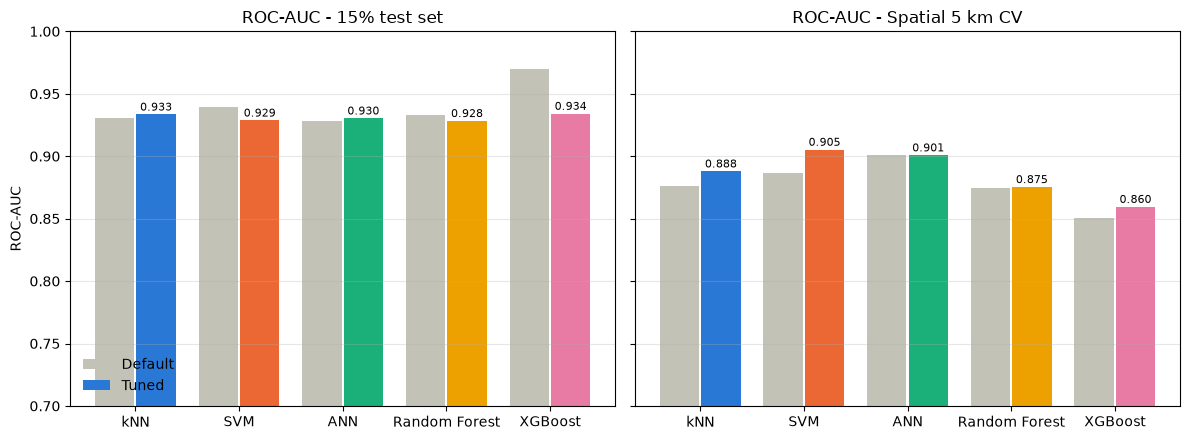


Best on unseen areas: SVM (spatial AUC 0.905, OA 0.830, Kappa 0.661)
Refitted on all points and saved to Results/best_model.joblib for the susceptibility map.


In [36]:
# Cell 13 - Hyperparameter tuning: default vs tuned settings (needs Cell 12)
# 15% of the points are held out as a test set; tuning uses 5-fold spatial block CV on the other 85%
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import (train_test_split, StratifiedGroupKFold,
                                     RandomizedSearchCV, cross_val_predict)
from xgboost import XGBClassifier

assert 'MODELS' in globals() and 'blocks' in globals(), "Run Cell 12 first"

N_ITER = 20  # settings tried per model
TEST_SIZE = 0.15

X_tr, X_te, y_tr, y_te, g_tr, g_te = train_test_split(
    X, y, blocks, test_size=TEST_SIZE, stratify=y, random_state=7)
print(f"Training: {len(y_tr)} points | Test (held out): {len(y_te)} points")
cv_tune = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)

# search space for each model (SVM tuned without calibration, added back afterwards)
SEARCH = {
    'kNN': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {'kneighborsclassifier__n_neighbors': randint(5, 61),
             'kneighborsclassifier__weights': ['uniform', 'distance'],
             'kneighborsclassifier__p': [1, 2]}),
    'SVM': (make_pipeline(StandardScaler(), SVC()),
            {'svc__C': loguniform(0.1, 100),
             'svc__gamma': loguniform(1e-3, 1)}),
    'ANN': (make_pipeline(StandardScaler(),
                          MLPClassifier(early_stopping=True, max_iter=500, random_state=42)),
            {'mlpclassifier__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
             'mlpclassifier__alpha': loguniform(1e-5, 1e-1),
             'mlpclassifier__learning_rate_init': loguniform(1e-4, 1e-2)}),
    'Random Forest': (RandomForestClassifier(n_jobs=1, random_state=42),
                      {'n_estimators': [300, 500, 800],
                       'max_depth': [None, 8, 12, 20, 30],
                       'min_samples_leaf': [1, 2, 5, 10, 20],
                       'max_features': ['sqrt', 'log2', 0.5]}),
    'XGBoost': (XGBClassifier(eval_metric='logloss', n_jobs=1, random_state=42),
                {'n_estimators': randint(200, 801),
                 'max_depth': randint(3, 9),
                 'learning_rate': loguniform(0.01, 0.2),
                 'subsample': uniform(0.6, 0.4),
                 'colsample_bytree': uniform(0.5, 0.5),
                 'min_child_weight': randint(1, 11),
                 'reg_lambda': loguniform(0.5, 5)}),
}

tuned, best_params = {}, {}
for name, (base, grid) in SEARCH.items():
    t0 = time.time()
    search = RandomizedSearchCV(base, grid, n_iter=N_ITER, scoring='roc_auc',
                                cv=cv_tune, n_jobs=-1, random_state=7, refit=False)
    search.fit(X_tr, y_tr, groups=g_tr)
    model = clone(base).set_params(**search.best_params_)
    if name == 'SVM':
        svc = model.named_steps['svc']
        model = make_pipeline(StandardScaler(),
                              CalibratedClassifierCV(svc, ensemble=False))
    tuned[name] = model
    best_params[name] = {k.split('__')[-1]: (round(float(v), 5) if isinstance(v, float)
                                             else int(v) if isinstance(v, (int, np.integer)) else v)
                         for k, v in search.best_params_.items()}
    print(f"{name:14s} tuned in {(time.time() - t0) / 60:4.1f} min | "
          f"validation AUC {search.best_score_:.3f} | {best_params[name]}")

# compare default vs tuned
rows, prob_test, prob_spatial = [], {}, {}
cv_eval = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)  # same folds as Cell 12 test B
for name in SEARCH:
    for version, model in [('Default', MODELS[name]), ('Tuned', tuned[name])]:
        fitted_m = clone(model).fit(X_tr, y_tr)
        p_test = fitted_m.predict_proba(X_te)[:, 1]
        p_sp = cross_val_predict(clone(model), X, y, groups=blocks, cv=cv_eval,
                                 method='predict_proba')[:, 1]
        if version == 'Tuned':
            prob_test[name], prob_spatial[name] = p_test, p_sp
        for test_name, yt, p in [('15% test set', y_te, p_test),
                                 ('Spatial 5 km CV', y, p_sp)]:
            rows.append({'Model': name, 'Version': version, 'Test': test_name, **score(yt, p)})
    print(f"compared {name}")

tuning = pd.DataFrame(rows)
tuning.to_csv(RESULTS_DIR / "tuning_default_vs_tuned.csv", index=False)
pd.DataFrame(best_params).T.to_csv(RESULTS_DIR / "tuning_best_settings.csv")

summary = tuning.pivot_table(index='Model', columns=['Test', 'Version'], values='ROC_AUC').round(3)
print("\nROC-AUC, default vs tuned:")
print(summary.to_string())
print("\nFull table (OA, Kappa, F1, ROC-AUC):")
display(tuning.round(3))

# figure: default vs tuned
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
names = list(SEARCH)
xpos = np.arange(len(names))
for ax, test_name in zip(axes, ['15% test set', 'Spatial 5 km CV']):
    d = tuning[tuning.Test == test_name].set_index(['Model', 'Version'])['ROC_AUC']
    ax.bar(xpos - 0.2, [d[(n, 'Default')] for n in names], 0.38, color='#c3c2b7', label='Default')
    ax.bar(xpos + 0.2, [d[(n, 'Tuned')] for n in names], 0.38,
           color=[COLORS[n] for n in names], label='Tuned')
    for i, n in enumerate(names):
        ax.text(i + 0.2, d[(n, 'Tuned')] + 0.003, f"{d[(n, 'Tuned')]:.3f}",
                ha='center', fontsize=8)
    ax.set_xticks(xpos, names)
    ax.set_title(f'ROC-AUC - {test_name}')
    ax.set_ylim(0.7, 1.0)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('ROC-AUC')
axes[0].legend(frameon=False, loc='lower left')
fig.tight_layout(); fig.savefig(RESULTS_DIR / "tuning_default_vs_tuned.png", dpi=300); plt.show()

# final model = best tuned AUC on the spatial test
sp = tuning[(tuning.Test == 'Spatial 5 km CV') & (tuning.Version == 'Tuned')].set_index('Model')
best_name = sp['ROC_AUC'].idxmax()
best_model = clone(tuned[best_name]).fit(X, y)  # refit on all points for the map
joblib.dump({'model': best_model, 'features': FEATURES, 'name': best_name},
            RESULTS_DIR / "best_model.joblib")
print(f"\nBest on unseen areas: {best_name} "
      f"(spatial AUC {sp.loc[best_name, 'ROC_AUC']:.3f}, OA {sp.loc[best_name, 'OA']:.3f}, "
      f"Kappa {sp.loc[best_name, 'Kappa']:.3f})")
print("Refitted on all points and saved to Results/best_model.joblib for the susceptibility map.")

**Result:**
- 7,391 points were used for tuning and 1,305 were kept aside as the test set.
- Tuning changes the results only a little (largest gain 0.019, for SVM), so the default settings were already reasonable.
- XGBoost's random-test score went down after tuning (0.969 → 0.934) while its spatial score went up slightly (0.851 → 0.860): the tuned version over-fits less.
- The tuned SVM has the best spatial AUC (0.905), with OA 83.0% and Kappa 0.66 ("substantial" agreement), so it is the final model, saved as `Results/best_model.joblib`.
- In the bar chart, grey bars are the default settings and coloured bars the tuned ones; the right panel (spatial CV) is the one that matters.

Model: SVM | features: ['ndvi', 'ndwi', 'ndbi', 'elevation', 'slope', 'plan_curvature', 'twi', 'drainage_density', 'distance_to_river', 'distance_to_road', 'soil_clay', 'mean_annual_rainfall_mm', 'northness', 'eastness']
Grid: 1509 x 1795 pixels (2.7 million) at 30 m
[ 0.4 min] downloaded tile 1/12
[ 1.0 min] downloaded tile 2/12
[ 1.5 min] downloaded tile 3/12
[ 1.8 min] downloaded tile 4/12
[ 3.2 min] downloaded tile 5/12
[ 3.6 min] downloaded tile 6/12
[ 4.9 min] downloaded tile 7/12
[ 5.3 min] downloaded tile 8/12
[ 5.8 min] downloaded tile 9/12
[ 6.3 min] downloaded tile 10/12
[ 7.6 min] downloaded tile 11/12
[ 9.0 min] downloaded tile 12/12
Valid pixels: 2,622,658 of 2,622,658 inside the AOI
[10.2 min] predicted 200,000/2,622,658 pixels
[11.5 min] predicted 400,000/2,622,658 pixels
[12.7 min] predicted 600,000/2,622,658 pixels
[14.1 min] predicted 800,000/2,622,658 pixels
[15.4 min] predicted 1,000,000/2,622,658 pixels
[16.8 min] predicted 1,200,000/2,622,658 pixels
[18.2 min] pr

,Zone,Area_km2,Area_%,Landslides,Landslides_%,Frequency_ratio
0,Very Low,1179.53,49.97,133,3.06,0.06
1,Low,442.97,18.77,212,4.87,0.26
2,Moderate,268.43,11.37,380,8.73,0.77
3,High,223.17,9.45,699,16.06,1.70
4,Very High,246.29,10.43,2928,67.28,6.45


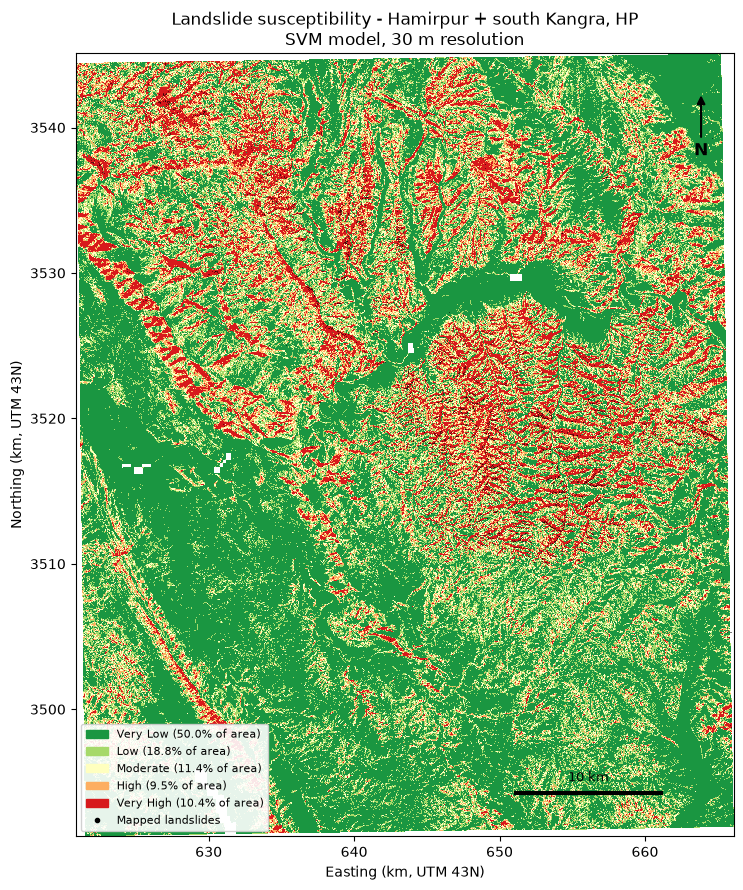

Saved Results/susceptibility_map.png (600 dpi). Total time 26.3 min


In [37]:
# Cell 14 - Susceptibility map: run the best model on every 30 m pixel (2024 imagery)
# Zones: Very Low < 0.2 < Low < 0.4 < Moderate < 0.6 < High < 0.8 < Very High
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from pyproj import Transformer

MAP_STACK = stack_2024
PIXEL = 30
TILE = 512
CLASS_BREAKS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0001]
CLASS_NAMES = ['Very Low', 'Low', 'Moderate', 'High', 'Very High']
CLASS_COLORS = ['#1a9641', '#a6d96a', '#ffffbf', '#fdae61', '#d7191c']

saved = joblib.load(RESULTS_DIR / "best_model.joblib")
model, model_features, model_name = saved['model'], saved['features'], saved['name']
print(f"Model: {model_name} | features: {model_features}")

# pixel grid in UTM 43N
to_utm = Transformer.from_crs("EPSG:4326", EPSG_CODE, always_xy=True)
lon0, lat0, lon1, lat1 = STUDY_AREA_COORDS
xs, ys = to_utm.transform([lon0, lon1, lon0, lon1], [lat0, lat0, lat1, lat1])
x_min = np.floor(min(xs) / PIXEL) * PIXEL
y_max = np.ceil(max(ys) / PIXEL) * PIXEL
width = int(np.ceil((max(xs) - x_min) / PIXEL))
height = int(np.ceil((y_max - min(ys)) / PIXEL))
print(f"Grid: {width} x {height} pixels ({width * height / 1e6:.1f} million) at {PIXEL} m")

# 'valid' band marks pixels that have data (masked pixels come back as 0)
raw_bands = [b for b in FEATURE_BANDS]
img = (MAP_STACK.select(raw_bands).toFloat().unmask(0)
       .addBands(MAP_STACK.select(raw_bands).mask().reduce(ee.Reducer.min())
                 .unmask(0).rename('valid').toFloat()))
img = img.clip(AOI)

stack = np.full((height, width, len(raw_bands)), np.nan, dtype=np.float32)
valid = np.zeros((height, width), dtype=bool)
t0 = time.time()
tiles = [(r, c) for r in range(0, height, TILE) for c in range(0, width, TILE)]
for k, (r, c) in enumerate(tiles, 1):
    h, w = min(TILE, height - r), min(TILE, width - c)
    grid = {'dimensions': {'width': w, 'height': h},
            'affineTransform': {'scaleX': PIXEL, 'shearX': 0, 'translateX': x_min + c * PIXEL,
                                'shearY': 0, 'scaleY': -PIXEL, 'translateY': y_max - r * PIXEL},
            'crsCode': EPSG_CODE}
    for attempt in range(3):
        try:
            arr = ee.data.computePixels({'expression': img, 'fileFormat': 'NUMPY_NDARRAY',
                                         'grid': grid})
            break
        except ee.EEException as e:
            if attempt == 2:
                raise
            print(f"   tile {k}: {str(e)[:60]} - retrying")
            time.sleep(5)
    stack[r:r + h, c:c + w, :] = np.stack([arr[b] for b in raw_bands], axis=-1)
    valid[r:r + h, c:c + w] = arr['valid'] > 0
    print(f"[{(time.time() - t0) / 60:4.1f} min] downloaded tile {k}/{len(tiles)}")

# same aspect split as Cell 12
cols = {b: stack[..., i] for i, b in enumerate(raw_bands)}
if 'northness' in model_features:
    rad = np.radians(cols['aspect'])
    cols['northness'], cols['eastness'] = np.cos(rad), np.sin(rad)
X_map = np.stack([cols[f][valid] for f in model_features], axis=1)
ok = np.isfinite(X_map).all(axis=1)
print(f"Valid pixels: {ok.sum():,} of {valid.sum():,} inside the AOI")

# predict in chunks
prob_valid = np.full(len(X_map), np.nan, dtype=np.float32)
idx = np.flatnonzero(ok)
CHUNK = 200_000
for s in range(0, len(idx), CHUNK):
    part = idx[s:s + CHUNK]
    prob_valid[part] = model.predict_proba(X_map[part])[:, 1]
    print(f"[{(time.time() - t0) / 60:4.1f} min] predicted {min(s + CHUNK, len(idx)):,}/{len(idx):,} pixels")

prob = np.full((height, width), np.nan, dtype=np.float32)
prob[valid] = prob_valid
zones = np.digitize(prob, CLASS_BREAKS[1:-1]).astype(np.float32) + 1  # zones 1..5
zones[~np.isfinite(prob)] = np.nan

# save GeoTIFFs
transform_gdal = (x_min, PIXEL, 0, y_max, 0, -PIXEL)
try:
    import rasterio
    from rasterio.transform import from_origin
    profile = dict(driver='GTiff', height=height, width=width, count=1, crs=EPSG_CODE,
                   transform=from_origin(x_min, y_max, PIXEL, PIXEL), compress='deflate')
    with rasterio.open(RESULTS_DIR / "susceptibility_probability.tif", 'w',
                       dtype='float32', nodata=np.nan, **profile) as dst:
        dst.write(prob, 1)
    with rasterio.open(RESULTS_DIR / "susceptibility_zones.tif", 'w',
                       dtype='uint8', nodata=0, **profile) as dst:
        dst.write(np.nan_to_num(zones, nan=0).astype('uint8'), 1)
    print("Saved GeoTIFFs: Results/susceptibility_probability.tif, susceptibility_zones.tif")
except ImportError:
    np.save(RESULTS_DIR / "susceptibility_probability.npy", prob)
    print("rasterio not installed - saved Results/susceptibility_probability.npy instead. "
          "Run  %pip install rasterio  and re-run this cell to get GeoTIFFs for QGIS.")

# zone statistics and frequency ratio
px_km2 = PIXEL * PIXEL / 1e6
slides = df_ml[df_ml.label == 1]
sx, sy = to_utm.transform(slides.lon.to_numpy(), slides.lat.to_numpy())
col_i = ((np.asarray(sx) - x_min) // PIXEL).astype(int)
row_i = ((y_max - np.asarray(sy)) // PIXEL).astype(int)
inside = (row_i >= 0) & (row_i < height) & (col_i >= 0) & (col_i < width)
slide_zone = zones[row_i[inside], col_i[inside]]
slide_zone = slide_zone[np.isfinite(slide_zone)]

stats = []
for z, name in enumerate(CLASS_NAMES, 1):
    area_px = int(np.nansum(zones == z))
    n_sl = int((slide_zone == z).sum())
    stats.append({'Zone': name, 'Area_km2': area_px * px_km2,
                  'Area_%': 100 * area_px / np.isfinite(zones).sum(),
                  'Landslides': n_sl, 'Landslides_%': 100 * n_sl / max(len(slide_zone), 1)})
stats = pd.DataFrame(stats)
stats['Frequency_ratio'] = stats['Landslides_%'] / stats['Area_%'].replace(0, np.nan)
stats.to_csv(RESULTS_DIR / "susceptibility_zone_stats.csv", index=False)
print("\nZone statistics (landslides = all mapped slides used in training):")
display(stats.round(2))

# map figure (600 dpi)
extent_km = [x_min / 1000, (x_min + width * PIXEL) / 1000,
             (y_max - height * PIXEL) / 1000, y_max / 1000]
fig, ax = plt.subplots(figsize=(8, 9))
ax.imshow(zones, cmap=ListedColormap(CLASS_COLORS),
          norm=BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5], 5),
          extent=extent_km, interpolation='nearest')
ax.scatter(np.asarray(sx)[inside] / 1000, np.asarray(sy)[inside] / 1000, s=0.4, c='black',
           alpha=0.5, linewidths=0, label='Mapped landslides (Bhuvan)')
ax.set_xlabel('Easting (km, UTM 43N)')
ax.set_ylabel('Northing (km, UTM 43N)')
ax.set_title(f'Landslide susceptibility - Hamirpur + south Kangra, HP\n'
             f'{model_name} model, {PIXEL} m resolution')
handles = [Patch(color=c, label=f'{n} ({stats.loc[i, "Area_%"]:.1f}% of area)')
           for i, (n, c) in enumerate(zip(CLASS_NAMES, CLASS_COLORS))]
handles.append(plt.Line2D([], [], marker='o', ls='', color='black', markersize=3,
                          label='Mapped landslides'))
ax.legend(handles=handles, loc='lower left', fontsize=8, framealpha=0.9)
# north arrow and 10 km scale bar
ax.annotate('N', xy=(0.95, 0.95), xytext=(0.95, 0.87), xycoords='axes fraction',
            ha='center', fontsize=12, fontweight='bold',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.5))
sb_x, sb_y = extent_km[1] - 15, extent_km[2] + 3
ax.plot([sb_x, sb_x + 10], [sb_y, sb_y], color='black', lw=3)
ax.text(sb_x + 5, sb_y + 0.8, '10 km', ha='center', fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "susceptibility_map.png", dpi=600)
plt.show()
print(f"Saved Results/susceptibility_map.png (600 dpi). Total time {(time.time() - t0) / 60:.1f} min")

**Result:**
- The tuned SVM was applied to all 2.62 million pixels of the 30 m grid.
- About half of the area (50%) is Very Low, and 19.9% is High or Very High.
- The frequency ratio rises from 0.06 (Very Low) to 6.45 (Very High): the Very High zone has about 6.5 times more landslides than its size alone would suggest, and 83.3% of the mapped landslides fall in the High and Very High zones. These landslides were also used for training, so this is a consistency check, not an independent test.
- On the map, the red and orange zones follow the steep, cut hills east of the Beas and the Shivalik ridges; green is valleys and terraces.

12 HP districts loaded; overlapping the study area: Bilaspur, Hamirpur, Kangra, Mandi, Una


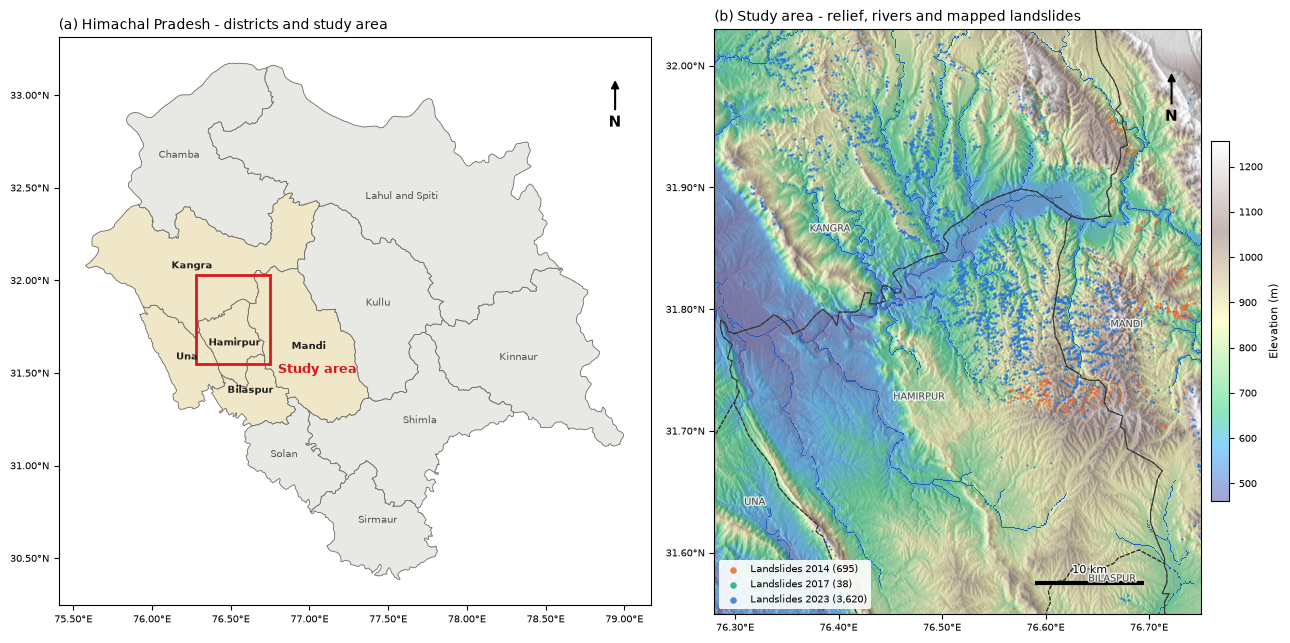

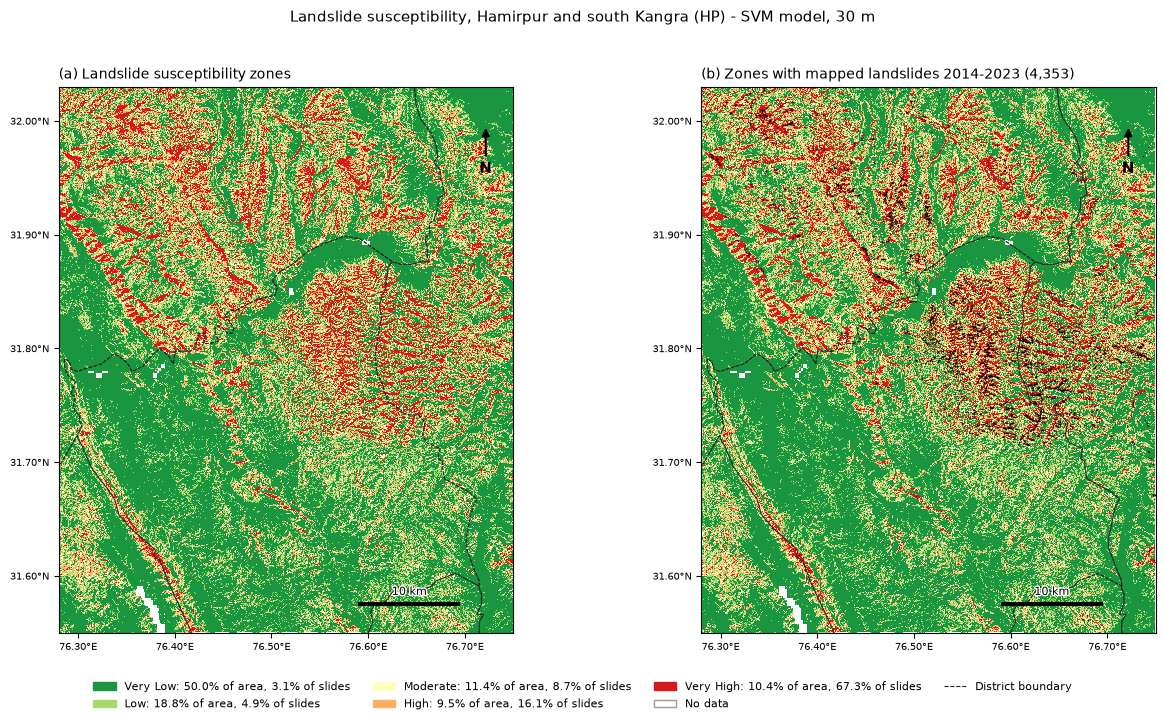

Saved Results/fig_study_area.png and Results/fig_susceptibility_final.png (600 dpi)


In [38]:
# Cell 15 - Report maps (600 dpi): study-area location map and final susceptibility map
# Needs Cells 1-2 and the files saved by Cells 11 and 14
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from pathlib import Path
from shapely.geometry import shape, box, MultiPolygon
import rasterio
from rasterio.warp import reproject, Resampling, calculate_default_transform

RESULTS_DIR = Path("Results")
lon0, lat0, lon1, lat1 = STUDY_AREA_COORDS
ASPECT = 1 / np.cos(np.radians((lat0 + lat1) / 2))  # 1 km east = 1 km north on screen
SEASON_COLORS = {2014: '#eb6834', 2017: '#1baf7a', 2023: '#2a78d6'}
CLASS_NAMES = ['Very Low', 'Low', 'Moderate', 'High', 'Very High']
CLASS_COLORS = ['#1a9641', '#a6d96a', '#ffffbf', '#fdae61', '#d7191c']

deg_e = FuncFormatter(lambda v, _: f"{v:.2f}°E")
deg_n = FuncFormatter(lambda v, _: f"{v:.2f}°N")

def draw_geom(ax, geom, **kw):
    polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
    for p in polys:
        x, y = p.exterior.xy
        ax.plot(x, y, **kw)

def add_north_arrow(ax, x=0.94, y=0.93):
    ax.annotate('N', xy=(x, y), xytext=(x, y - 0.08), xycoords='axes fraction',
                ha='center', va='center', fontsize=11, fontweight='bold',
                arrowprops=dict(arrowstyle='-|>', color='black', lw=1.5))

def add_scale_bar(ax, km, lon_start, lat_at):
    dlon = km / (111.32 * np.cos(np.radians(lat_at)))
    ax.plot([lon_start, lon_start + dlon], [lat_at, lat_at], color='black', lw=3,
            solid_capstyle='butt')
    ax.text(lon_start + dlon / 2, lat_at + 0.006, f'{km} km', ha='center', va='bottom',
            fontsize=8, path_effects=[pe.withStroke(linewidth=2, foreground='white')])

# district boundaries of Himachal Pradesh
def polygons_only(g):
    # GAUL sometimes returns GeometryCollections - keep only the polygon parts
    if g is None or g.is_empty:
        return None
    if g.geom_type in ('Polygon', 'MultiPolygon'):
        return g
    parts = []
    for sub in getattr(g, 'geoms', []):
        p = polygons_only(sub)
        if p is not None:
            parts.extend([p] if p.geom_type == 'Polygon' else list(p.geoms))
    return MultiPolygon(parts) if parts else None

def clean(g):
    g = polygons_only(g)
    if g is not None and not g.is_valid:
        g = polygons_only(g.buffer(0))
    return g

def get_hp_districts():
    for fc_id, state_prop, name_prop in [
            ('FAO/GAUL_SIMPLIFIED_500m/2015/level2', 'ADM1_NAME', 'ADM2_NAME'),
            ('FAO/GAUL/2015/level2', 'ADM1_NAME', 'ADM2_NAME')]:
        try:
            fc = ee.FeatureCollection(fc_id).filter(ee.Filter.eq(state_prop, 'Himachal Pradesh'))
            info = fc.select([name_prop]).getInfo()
            out = [(f['properties'][name_prop], clean(shape(f['geometry'])))
                   for f in info['features']]
            out = [(n, g) for n, g in out if g is not None]
            if out:
                return out
        except Exception as e:
            print(f"{fc_id}: {str(e)[:80]}")
    raise RuntimeError("Could not load district boundaries from Earth Engine")

districts = get_hp_districts()
with open(RESULTS_DIR / "hp_districts.geojson", 'w') as fh:  # reused by Cell 17
    json.dump({'type': 'FeatureCollection',
               'features': [{'type': 'Feature', 'properties': {'district': n},
                             'geometry': g.__geo_interface__} for n, g in districts]}, fh)
aoi_box = box(lon0, lat0, lon1, lat1)
in_aoi = [(n, g) for n, g in districts if g.intersects(aoi_box)]
print(f"{len(districts)} HP districts loaded; overlapping the study area: "
      f"{', '.join(n for n, _ in in_aoi)}")

# relief, elevation and rivers
STEP = 0.0005  # ~50 m
w_px, h_px = int(round((lon1 - lon0) / STEP)), int(round((lat1 - lat0) / STEP))
dem = ee.Image('USGS/SRTMGL1_003')
streams = ee.Image('MERIT/Hydro/v1_0_1').select('upa').gt(25)
relief_img = (ee.Terrain.hillshade(dem).rename('hillshade').toFloat()
              .addBands(dem.rename('elev').toFloat())
              .addBands(streams.unmask(0).rename('river').toFloat()))
relief = ee.data.computePixels({
    'expression': relief_img, 'fileFormat': 'NUMPY_NDARRAY',
    'grid': {'dimensions': {'width': w_px, 'height': h_px},
             'affineTransform': {'scaleX': STEP, 'shearX': 0, 'translateX': lon0,
                                 'shearY': 0, 'scaleY': -STEP, 'translateY': lat1},
             'crsCode': 'EPSG:4326'}})
extent_aoi = [lon0, lon1, lat0, lat1]

# landslide points by season
df_pts = df_ml if 'df_ml' in globals() else pd.read_csv("Bhuvan_inventory/ml_dataset_AOI.csv")
slides = df_pts[df_pts.label == 1]

# Figure A: location map
fig, (axa, axb) = plt.subplots(1, 2, figsize=(13, 6.8),
                               gridspec_kw={'width_ratios': [1.15, 1]})
for name, geom in districts:
    hit = geom.intersects(aoi_box)
    polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
    for p in polys:
        x, y = p.exterior.xy
        axa.fill(x, y, color='#f0e6c8' if hit else '#e8e8e4', ec='#6b6b66', lw=0.6)
    lab = geom.representative_point()
    axa.text(lab.x, lab.y, name, ha='center', va='center', fontsize=7,
             fontweight='bold' if hit else 'normal', color='#222222' if hit else '#55554f')
axa.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, fill=False, ec='#d7191c', lw=2))
axa.text(lon1 + 0.05, lat0 - 0.05, 'Study area', color='#d7191c', fontsize=9, fontweight='bold')
axa.set_aspect(ASPECT)
axa.xaxis.set_major_formatter(deg_e); axa.yaxis.set_major_formatter(deg_n)
axa.tick_params(labelsize=7)
axa.set_title('(a) Himachal Pradesh - districts and study area', fontsize=10, loc='left')
add_north_arrow(axa)

axb.imshow(relief['hillshade'], cmap='gray', extent=extent_aoi, interpolation='bilinear')
e_lo, e_hi = np.nanpercentile(relief['elev'], [1, 99])
elev_im = axb.imshow(relief['elev'], cmap='terrain', alpha=0.45, extent=extent_aoi,
                     vmin=e_lo, vmax=e_hi, interpolation='bilinear')
river = np.ma.masked_where(relief['river'] < 0.5, relief['river'])
axb.imshow(river, cmap=ListedColormap(['#1f5fbf']), extent=extent_aoi, interpolation='nearest')
for name, geom in in_aoi:
    draw_geom(axb, geom, color='#333333', lw=0.8, ls='--')  # axis limits clip it to the box
    c = geom.intersection(aoi_box).representative_point()
    axb.text(c.x, c.y, name.upper(), fontsize=7, ha='center', color='#222222', alpha=0.8,
             path_effects=[pe.withStroke(linewidth=2, foreground='white')])
for season, col in SEASON_COLORS.items():
    s = slides[slides.season == season]
    axb.scatter(s.lon, s.lat, s=2.5, c=col, linewidths=0, alpha=0.85,
                label=f'Landslides {season} ({len(s):,})')
axb.set_xlim(lon0, lon1); axb.set_ylim(lat0, lat1); axb.set_aspect(ASPECT)
axb.xaxis.set_major_formatter(deg_e); axb.yaxis.set_major_formatter(deg_n)
axb.tick_params(labelsize=7)
axb.set_title('(b) Study area - relief, rivers and mapped landslides', fontsize=10, loc='left')
leg = axb.legend(loc='lower left', fontsize=7, markerscale=3, framealpha=0.9)
leg.get_frame().set_linewidth(0)
cb = fig.colorbar(elev_im, ax=axb, fraction=0.035, pad=0.02)
cb.set_label('Elevation (m)', fontsize=8); cb.ax.tick_params(labelsize=7)
add_north_arrow(axb)
add_scale_bar(axb, 10, lon1 - 0.16, lat0 + 0.025)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_study_area.png", dpi=600, bbox_inches='tight')
plt.show()

# Figure B: susceptibility zones re-projected to lat/long
with rasterio.open(RESULTS_DIR / "susceptibility_zones.tif") as src:
    tr, w_ll, h_ll = calculate_default_transform(src.crs, 'EPSG:4326', src.width, src.height,
                                                 *src.bounds, resolution=0.0003)
    zones_ll = np.zeros((h_ll, w_ll), dtype='uint8')
    reproject(src.read(1), zones_ll, src_transform=src.transform, src_crs=src.crs,
              dst_transform=tr, dst_crs='EPSG:4326', resampling=Resampling.nearest,
              src_nodata=0, dst_nodata=0)
ext_ll = [tr.c, tr.c + w_ll * tr.a, tr.f + h_ll * tr.e, tr.f]
stats = pd.read_csv(RESULTS_DIR / "susceptibility_zone_stats.csv")

zone_cmap = ListedColormap(['#ffffff'] + CLASS_COLORS)  # 0 = no data
zone_norm = BoundaryNorm(np.arange(-0.5, 6.5), 6)
fig, axes = plt.subplots(1, 2, figsize=(13, 7.2))
for k, ax in enumerate(axes):
    ax.imshow(zones_ll, cmap=zone_cmap, norm=zone_norm, extent=ext_ll, interpolation='nearest')
    for name, geom in in_aoi:
        draw_geom(ax, geom, color='#222222', lw=0.7, ls='--')
    if k == 1:
        ax.scatter(slides.lon, slides.lat, s=1.2, c='black', linewidths=0, alpha=0.7)
    ax.set_xlim(lon0, lon1); ax.set_ylim(lat0, lat1); ax.set_aspect(ASPECT)
    ax.xaxis.set_major_formatter(deg_e); ax.yaxis.set_major_formatter(deg_n)
    ax.tick_params(labelsize=7)
    add_north_arrow(ax)
    add_scale_bar(ax, 10, lon1 - 0.16, lat0 + 0.025)
axes[0].set_title('(a) Landslide susceptibility zones', fontsize=10, loc='left')
axes[1].set_title(f'(b) Zones with mapped landslides 2014-2023 ({len(slides):,})',
                  fontsize=10, loc='left')
handles = [Patch(color=c, label=f"{n}: {stats.loc[i, 'Area_%']:.1f}% of area, "
                                f"{stats.loc[i, 'Landslides_%']:.1f}% of slides")
           for i, (n, c) in enumerate(zip(CLASS_NAMES, CLASS_COLORS))]
handles.append(Patch(facecolor='white', edgecolor='#999999', label='No data'))
handles.append(plt.Line2D([], [], ls='--', color='#222222', lw=0.8, label='District boundary'))
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=8, frameon=False)
import joblib
model_name = joblib.load(RESULTS_DIR / "best_model.joblib")['name']
fig.suptitle(f"Landslide susceptibility, Hamirpur and south Kangra (HP) - {model_name} model, 30 m",
             fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
fig.savefig(RESULTS_DIR / "fig_susceptibility_final.png", dpi=600, bbox_inches='tight')
plt.show()
print("Saved Results/fig_study_area.png and Results/fig_susceptibility_final.png (600 dpi)")

**Result:** two 600 dpi figures for the report. (a) Where the study area is in Himachal Pradesh, and its relief with the landslides by season. (b) The final susceptibility map in latitude/longitude with district boundaries. The study area touches five districts: Bilaspur, Hamirpur, Kangra, Mandi and Una.

CHIRPS data check - years with missing daily images: none
(for comparison, PENTAD images per year: {2001: 72, 2002: 72, 2003: 72, 2004: 72, 2005: 72, 2006: 72, 2007: 72, 2008: 72, 2009: 72, 2010: 72, 2011: 72, 2012: 72, 2013: 72, 2014: 72, 2015: 72, 2016: 72, 2017: 72, 2018: 72, 2019: 72, 2020: 72, 2021: 72, 2022: 72, 2023: 72, 2024: 72, 2025: 72} )
Yearly values (NDVI, rainfall) and 5-yearly population:


,n_daily_images,ndvi,rain_annual_mm,rain_era5_annual_mm,rain_era5_monsoon_mm,rain_monsoon_mm,year
0,365,0.549,487.898,1411.208,1123.472,386.830,2001
1,365,0.560,411.686,1179.584,811.713,310.276,2002
2,365,0.560,453.480,1409.496,878.342,351.517,2003
3,366,0.589,433.623,1093.530,710.147,315.617,2004
4,365,0.592,430.928,1343.271,796.309,316.401,2005
5,365,0.598,539.716,1357.983,920.528,408.032,2006
6,365,0.607,475.240,1375.213,908.064,356.935,2007
7,366,0.585,492.117,1632.959,1189.428,360.663,2008
8,365,0.576,1536.024,1156.377,820.258,1200.522,2009
9,365,0.583,2075.451,1926.265,1582.200,1841.998,2010


,year,population
0,2000,793837.0
1,2005,844660.0
2,2010,885827.0
3,2015,920759.0
4,2020,951605.0
5,2025,972301.0


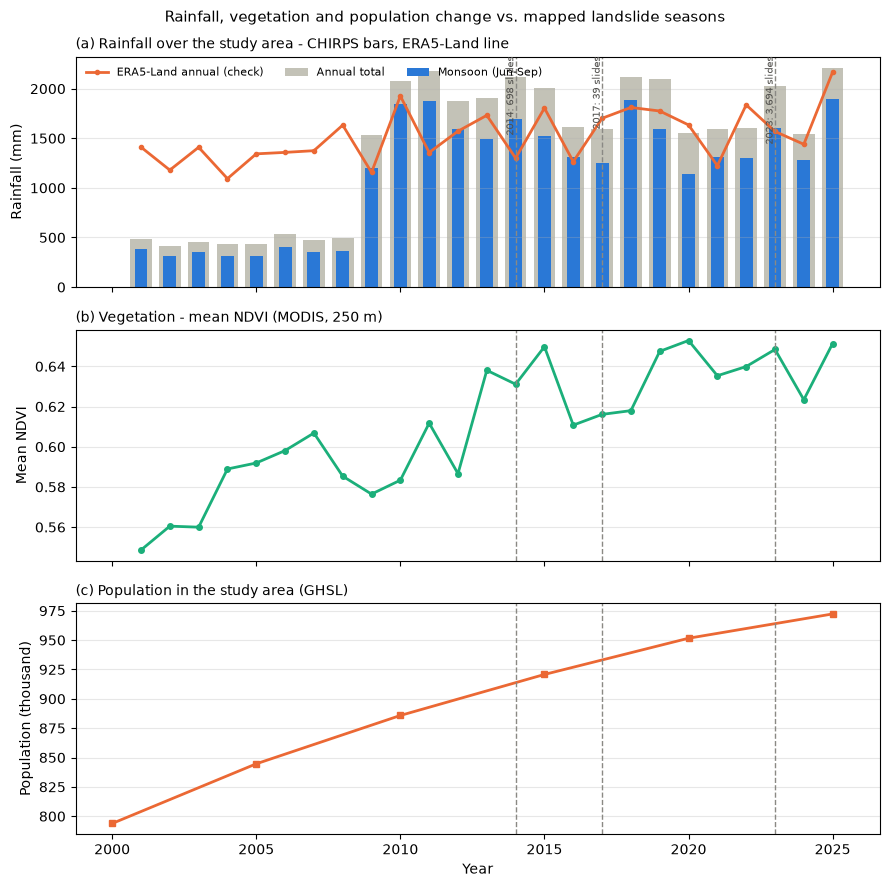

CHIRPS    mean annual rainfall: 2001-08 =   466 mm, 2009-25 =  1862 mm (ratio 4.00)
ERA5-Land mean annual rainfall: 2001-08 =  1350 mm, 2009-25 =  1604 mm (ratio 1.19)
If ERA5-Land shows no such jump, the 2001-08 CHIRPS values are a data artefact: use 2009 onwards for CHIRPS (Cell 7 does).
Monsoon rainfall (CHIRPS): mean 1518 mm (2009-2025); 2014: 1693 mm, 2017: 1248 mm, 2023: 1601 mm

Vegetation change 2005-07 -> 2019-21 (five equal-area classes) vs. 2023 landslides (FR > 1 = more slides than the area share alone would give):


,Class,Area_%,Slides_2023,Slides_%,Frequency_ratio
0,Q1: dNDVI min to +0.032,20.60,492,13.59,0.66
1,Q2: dNDVI +0.032 to +0.042,19.00,603,16.66,0.88
2,Q3: dNDVI +0.042 to +0.052,22.34,802,22.15,0.99
3,Q4: dNDVI +0.052 to +0.061,18.54,829,22.90,1.24
4,Q5: dNDVI +0.061 to max,19.51,894,24.70,1.27


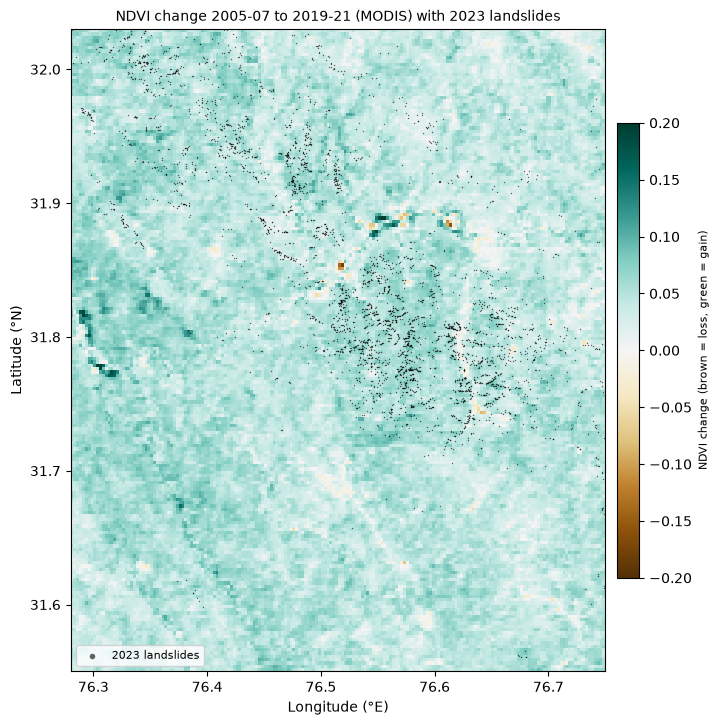


Earthquakes within 150 km, M>=3.0, 2005-2026: 101
mag
M3-4    19
M4-5    78
M5+      4

Largest 10:


,time,mag,depth,dist_km,place
36,2011-08-23 01:22:56.280000+00:00,5.1,14.6,148.6,"41 km S of Padam, India"
89,2025-03-13 21:20:05.314000+00:00,5.1,10.0,140.8,"50 km SSW of Padam, India"
34,2010-05-28 07:25:02.580000+00:00,5.0,18.8,145.2,"10 km SE of Rohru, India"
71,2020-02-26 15:04:08.953000+00:00,5.0,10.0,134.2,"47 km NNE of Chamba, India"
42,2013-06-04 17:34:50.750000+00:00,4.9,41.1,98.4,"41 km WNW of Kyelang, India"
49,2014-08-21 08:11:18.820000+00:00,4.9,10.0,60.5,"15 km NE of Dharamsala, India"
70,2019-09-09 06:40:33.517000+00:00,4.9,43.9,136.0,"43 km E of Bhadarw?h, India"
97,2026-06-05 16:34:36.164000+00:00,4.9,10.0,68.8,"32 km N of Pālampur, India"
2,2005-02-28 18:01:59.750000+00:00,4.8,12.0,83.4,"37 km W of Kyelang, India"
3,2005-04-14 07:11:27.170000+00:00,4.8,31.3,87.6,"21 km E of Chamba, India"


M4+ within 50 km of the study-area centre: 6


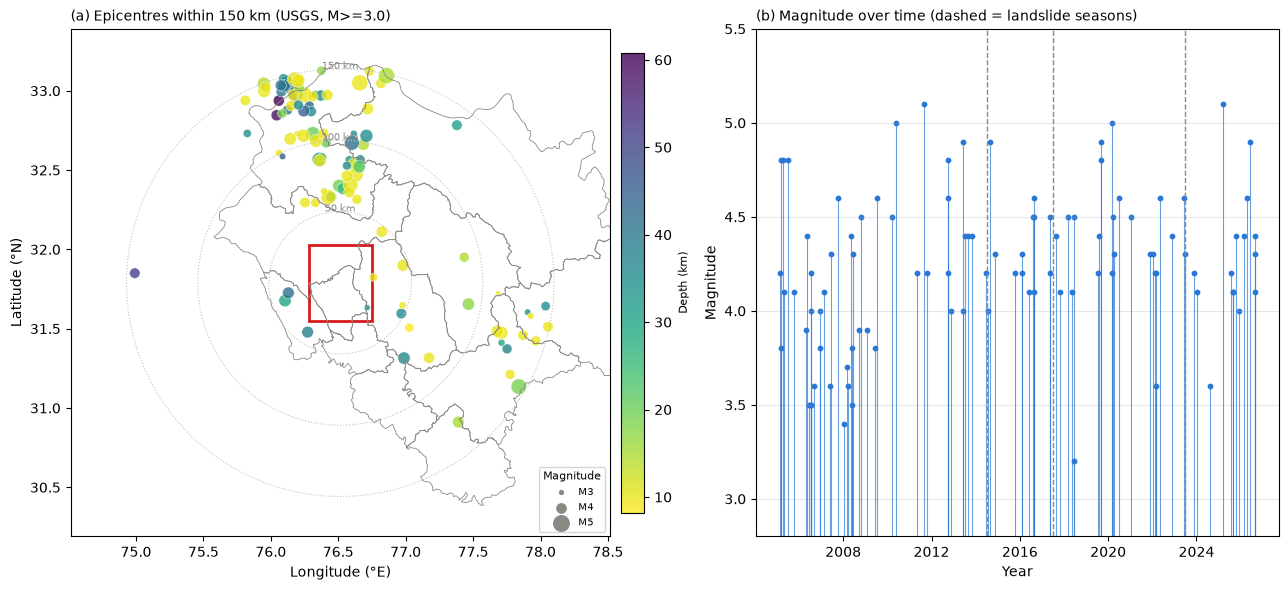

Saved to Results/: change_timeseries.csv, fig_change_timeseries.png, vegetation_change_vs_landslides.csv, fig_ndvi_change_2023_slides.png, earthquakes_usgs_150km.csv, fig_earthquakes.png


In [39]:
# Cell 16 - Change over the study period (vegetation, rainfall, population) and earthquakes
# MODIS NDVI, CHIRPS daily + ERA5-Land rainfall, GHSL population, USGS earthquakes within 150 km
import io
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date
from pathlib import Path
from shapely.geometry import shape

RESULTS_DIR = Path("Results")
lon0, lat0, lon1, lat1 = STUDY_AREA_COORDS
ASPECT = 1 / np.cos(np.radians((lat0 + lat1) / 2))
YEARS = list(range(2001, 2026))
SEASON_YEARS = [2014, 2017, 2023]
C_BLUE, C_ORANGE, C_GREEN, C_GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

modis = ee.ImageCollection('MODIS/061/MOD13Q1')
chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
chirps_pentad = ee.ImageCollection('UCSB-CHG/CHIRPS/PENTAD')  # only for the data check
# ERA5-Land as an independent check on CHIRPS
era5 = ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR').select('total_precipitation_sum')

def modis_ndvi(start, end):
    # keep good / marginal pixels only, scale to -1..1
    return (modis.filterDate(start, end)
            .map(lambda im: im.select('NDVI').updateMask(im.select('SummaryQA').lte(1)))
            .mean().multiply(0.0001))

def per_year(y):
    y = ee.Number(y)
    start, end = ee.Date.fromYMD(y, 1, 1), ee.Date.fromYMD(y.add(1), 1, 1)
    ndvi = modis_ndvi(start, end).reduceRegion(ee.Reducer.mean(), AOI, 250,
                                               maxPixels=1e9).get('NDVI')
    rain_year = chirps.filterDate(start, end).sum().reduceRegion(
        ee.Reducer.mean(), AOI, 5566, maxPixels=1e9).get('precipitation')
    rain_monsoon = chirps.filterDate(ee.Date.fromYMD(y, 6, 1), ee.Date.fromYMD(y, 10, 1)).sum() \
        .reduceRegion(ee.Reducer.mean(), AOI, 5566, maxPixels=1e9).get('precipitation')
    return ee.Feature(None, {'year': y, 'ndvi': ndvi, 'rain_annual_mm': rain_year,
                             'rain_monsoon_mm': rain_monsoon,
                             'rain_era5_annual_mm': era5.filterDate(start, end).sum().multiply(1000)
                             .reduceRegion(ee.Reducer.mean(), AOI, 11132, maxPixels=1e9)
                             .get('total_precipitation_sum'),
                             'rain_era5_monsoon_mm': era5.filterDate(ee.Date.fromYMD(y, 6, 1),
                                                                     ee.Date.fromYMD(y, 10, 1))
                             .sum().multiply(1000)
                             .reduceRegion(ee.Reducer.mean(), AOI, 11132, maxPixels=1e9)
                             .get('total_precipitation_sum'),
                             'n_daily_images': chirps.filterDate(start, end).size(),
                             'n_pentad_images': chirps_pentad.filterDate(start, end).size()})

series = pd.DataFrame([f['properties'] for f in
                       ee.FeatureCollection(ee.List(YEARS).map(per_year)).getInfo()['features']])
series = series.sort_values('year').reset_index(drop=True)
short = series[(series.n_daily_images < 360) & (series.year < date.today().year)]
print("CHIRPS data check - years with missing daily images:",
      'none' if short.empty else short[['year', 'n_daily_images']].to_dict('records'))
print("(for comparison, PENTAD images per year:", dict(zip(series.year, series.n_pentad_images)), ")")

pop_rows = []
for y in range(2000, 2026, 5):
    ghs = ee.Image(f'JRC/GHSL/P2023A/GHS_POP/{y}')
    total = ghs.reduceRegion(ee.Reducer.sum(), AOI, crs=ghs.projection(), maxPixels=1e9) \
        .get('population_count').getInfo()
    pop_rows.append({'year': y, 'population': total})
pop = pd.DataFrame(pop_rows)

# landslides per Bhuvan season inside the box
inv = pd.read_csv("Bhuvan_inventory/bhuvan_HP_landslides_2014_2017_2023.csv")
inv = inv[(inv.lon >= lon0) & (inv.lon <= lon1) & (inv.lat >= lat0) & (inv.lat <= lat1)]
slides_per_season = inv.groupby('year').size().to_dict()

series.merge(pop, on='year', how='left').to_csv(RESULTS_DIR / "change_timeseries.csv", index=False)
print("Yearly values (NDVI, rainfall) and 5-yearly population:")
display(series.drop(columns=['n_pentad_images']).round(3))
display(pop.round(0))

# figure: rainfall, vegetation and population vs the landslide seasons
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
ax = axes[0]
ax.bar(series.year, series.rain_annual_mm, color='#c3c2b7', width=0.75, label='Annual total')
ax.bar(series.year, series.rain_monsoon_mm, color=C_BLUE, width=0.45, label='Monsoon (Jun-Sep)')
ax.plot(series.year, series.rain_era5_annual_mm, color=C_ORANGE, lw=2, marker='o', ms=3,
        label='ERA5-Land annual (check)')
ax.set_ylabel('Rainfall (mm)')
ax.legend(frameon=False, fontsize=8, loc='upper left', ncol=3)
ax.set_title('(a) Rainfall over the study area - CHIRPS bars, ERA5-Land line', fontsize=10, loc='left')
ax = axes[1]
ax.plot(series.year, series.ndvi, color=C_GREEN, lw=2, marker='o', ms=4)
ax.set_ylabel('Mean NDVI')
ax.set_title('(b) Vegetation - mean NDVI (MODIS, 250 m)', fontsize=10, loc='left')
ax = axes[2]
ax.plot(pop.year, pop.population / 1e3, color=C_ORANGE, lw=2, marker='s', ms=5)
ax.set_ylabel('Population (thousand)')
ax.set_title('(c) Population in the study area (GHSL)', fontsize=10, loc='left')
ax.set_xlabel('Year')
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
    for y in SEASON_YEARS:
        ax.axvline(y, color=C_GREY, ls='--', lw=1)
for y in SEASON_YEARS:
    axes[0].text(y, axes[0].get_ylim()[1], f" {y}: {slides_per_season.get(y, 0):,} slides",
                 rotation=90, va='top', ha='right', fontsize=7, color='#52514e')
fig.suptitle('Rainfall, vegetation and population change vs. mapped landslide seasons',
             fontsize=11)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_change_timeseries.png", dpi=600)
plt.show()

ser = series.set_index('year')
for name, col in [('CHIRPS', 'rain_annual_mm'), ('ERA5-Land', 'rain_era5_annual_mm')]:
    early, late = ser.loc[2001:2008, col].mean(), ser.loc[2009:2025, col].mean()
    print(f"{name:9s} mean annual rainfall: 2001-08 = {early:5.0f} mm, 2009-25 = {late:5.0f} mm "
          f"(ratio {late / early:.2f})")
print("If ERA5-Land shows no such jump, the 2001-08 CHIRPS values are a data artefact: "
      "use 2009 onwards for CHIRPS (Cell 7 does).")
wet = series.set_index('year').rain_monsoon_mm
print(f"Monsoon rainfall (CHIRPS): mean {wet.loc[2009:].mean():.0f} mm (2009-2025); "
      + ", ".join(f"{y}: {wet.get(y, np.nan):.0f} mm" for y in SEASON_YEARS))

# vegetation change (2005-07 to 2019-21) vs 2023 landslides
d_ndvi = modis_ndvi('2019-01-01', '2022-01-01').subtract(
    modis_ndvi('2005-01-01', '2008-01-01')).rename('d_ndvi')
# the whole area greened, so the change is split into five equal-area classes
q = d_ndvi.reduceRegion(ee.Reducer.percentile([20, 40, 60, 80]), AOI, 250,
                        maxPixels=1e9).getInfo()
cuts = [q[f'd_ndvi_p{p}'] for p in (20, 40, 60, 80)]
veg_class = (ee.Image(0).where(d_ndvi.gt(cuts[0]), 1).where(d_ndvi.gt(cuts[1]), 2)
             .where(d_ndvi.gt(cuts[2]), 3).where(d_ndvi.gt(cuts[3]), 4)
             .updateMask(d_ndvi.mask()).rename('cls').toInt())
edges = [-np.inf] + cuts + [np.inf]
CLS_NAMES = {c: f"Q{c + 1}: dNDVI {edges[c]:+.3f} to {edges[c + 1]:+.3f}".replace('-inf', 'min')
             .replace('+inf', 'max') for c in range(5)}
hist = veg_class.reduceRegion(ee.Reducer.frequencyHistogram(), AOI, 250,
                              maxPixels=1e9).get('cls').getInfo()
s23 = df_ml[(df_ml.label == 1) & (df_ml.season == 2023)] if 'df_ml' in globals() else \
    pd.read_csv("Bhuvan_inventory/ml_dataset_AOI.csv").query("label == 1 and season == 2023")
pts = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.lon, r.lat])) for r in s23.itertuples()])
sampled = veg_class.sampleRegions(collection=pts, scale=250, geometries=False).getInfo()['features']
slide_cls = pd.Series([f['properties']['cls'] for f in sampled]).value_counts()
total_px = sum(hist.values())
veg_tab = pd.DataFrame([{'Class': CLS_NAMES[c],
                         'Area_%': 100 * hist.get(str(c), 0) / total_px,
                         'Slides_2023': int(slide_cls.get(c, 0)),
                         'Slides_%': 100 * slide_cls.get(c, 0) / max(slide_cls.sum(), 1)}
                        for c in range(5)])
veg_tab['Frequency_ratio'] = veg_tab['Slides_%'] / veg_tab['Area_%'].replace(0, np.nan)
veg_tab.to_csv(RESULTS_DIR / "vegetation_change_vs_landslides.csv", index=False)
print("\nVegetation change 2005-07 -> 2019-21 (five equal-area classes) vs. 2023 landslides "
      "(FR > 1 = more slides than the area share alone would give):")
display(veg_tab.round(2))

# map of NDVI change with the 2023 landslides
STEP = 0.0025  # ~250 m
grid = {'dimensions': {'width': int(round((lon1 - lon0) / STEP)),
                       'height': int(round((lat1 - lat0) / STEP))},
        'affineTransform': {'scaleX': STEP, 'shearX': 0, 'translateX': lon0,
                            'shearY': 0, 'scaleY': -STEP, 'translateY': lat1},
        'crsCode': 'EPSG:4326'}
d_arr = ee.data.computePixels({'expression': d_ndvi.unmask(-9).toFloat(),
                               'fileFormat': 'NUMPY_NDARRAY', 'grid': grid})['d_ndvi']
d_arr = np.where(d_arr < -5, np.nan, d_arr)
fig, ax = plt.subplots(figsize=(7, 7.5))
im = ax.imshow(d_arr, cmap='BrBG', vmin=-0.2, vmax=0.2, extent=[lon0, lon1, lat0, lat1],
               interpolation='nearest')
ax.scatter(s23.lon, s23.lat, s=1, c='black', linewidths=0, alpha=0.6, label='2023 landslides')
ax.set_aspect(ASPECT)
ax.set_title('NDVI change 2005-07 to 2019-21 (MODIS) with 2023 landslides', fontsize=10)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label('NDVI change (brown = loss, green = gain)', fontsize=8)
ax.legend(loc='lower left', fontsize=8, markerscale=4, frameon=True)
ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)')
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_ndvi_change_2023_slides.png", dpi=600)
plt.show()

# earthquakes from the USGS catalogue
lon_c, lat_c = (lon0 + lon1) / 2, (lat0 + lat1) / 2
RADIUS_KM, MIN_MAG = 150, 3.0
url = ("https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv"
       f"&starttime=2005-01-01&endtime={date.today().isoformat()}"
       f"&latitude={lat_c:.4f}&longitude={lon_c:.4f}&maxradiuskm={RADIUS_KM}"
       f"&minmagnitude={MIN_MAG}&orderby=time-asc")
with urllib.request.urlopen(url, timeout=60) as resp:
    eq = pd.read_csv(io.StringIO(resp.read().decode('utf-8')))
eq['time'] = pd.to_datetime(eq['time'])
eq['year'] = eq['time'].dt.year
eq['dist_km'] = 6371 * 2 * np.arcsin(np.sqrt(
    np.sin(np.radians(eq.latitude - lat_c) / 2) ** 2 +
    np.cos(np.radians(lat_c)) * np.cos(np.radians(eq.latitude)) *
    np.sin(np.radians(eq.longitude - lon_c) / 2) ** 2))
eq[['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'dist_km']] \
    .to_csv(RESULTS_DIR / "earthquakes_usgs_150km.csv", index=False)

bins = pd.cut(eq.mag, [MIN_MAG, 4, 5, 10], right=False, labels=['M3-4', 'M4-5', 'M5+'])
print(f"\nEarthquakes within {RADIUS_KM} km, M>={MIN_MAG}, 2005-{date.today().year}: {len(eq)}")
print(bins.value_counts().sort_index().to_string())
print("\nLargest 10:")
display(eq.nlargest(10, 'mag')[['time', 'mag', 'depth', 'dist_km', 'place']].round(1))
near = eq[(eq.mag >= 4) & (eq.dist_km <= 50)]
print(f"M4+ within 50 km of the study-area centre: {len(near)}")

with open(RESULTS_DIR / "hp_districts.geojson") as fh:
    hp = [shape(f['geometry']) for f in json.load(fh)['features']]
fig, (axm, axt) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1.1, 1]})
for g in hp:
    for p in ([g] if g.geom_type == 'Polygon' else list(g.geoms)):
        axm.plot(*p.exterior.xy, color='#8a8984', lw=0.6)
axm.add_patch(plt.Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, fill=False, ec='#d7191c', lw=2))
for r_km in (50, 100, 150):
    t = np.linspace(0, 2 * np.pi, 200)
    axm.plot(lon_c + r_km / (111.32 * np.cos(np.radians(lat_c))) * np.cos(t),
             lat_c + r_km / 111.32 * np.sin(t), color='#c3c2b7', lw=0.8, ls=':')
    axm.text(lon_c, lat_c + r_km / 111.32, f'{r_km} km', fontsize=7, color='#8a8984', ha='center')
sc = axm.scatter(eq.longitude, eq.latitude, s=(eq.mag - 2) ** 2.5 * 8, c=eq.depth,
                 cmap='viridis_r', alpha=0.8, edgecolors='white', linewidths=0.4)
fig.colorbar(sc, ax=axm, fraction=0.04, pad=0.02).set_label('Depth (km)', fontsize=8)
for m in (3, 4, 5):
    axm.scatter([], [], s=(m - 2) ** 2.5 * 8, c='#8a8984', label=f'M{m}')
axm.legend(title='Magnitude', fontsize=7, title_fontsize=8, loc='lower right', frameon=True)
axm.set_xlim(lon_c - 2.0, lon_c + 2.0); axm.set_ylim(lat_c - 1.6, lat_c + 1.6)
axm.set_aspect(ASPECT)
axm.set_xlabel('Longitude (°E)'); axm.set_ylabel('Latitude (°N)')
axm.set_title(f'(a) Epicentres within {RADIUS_KM} km (USGS, M>={MIN_MAG})', fontsize=10, loc='left')
axt.vlines(eq.time, MIN_MAG - 0.2, eq.mag, color=C_BLUE, lw=0.8, alpha=0.7)
axt.scatter(eq.time, eq.mag, s=10, color=C_BLUE)
for y in SEASON_YEARS:
    axt.axvline(pd.Timestamp(f'{y}-07-01'), color=C_GREY, ls='--', lw=1)
axt.set_ylim(MIN_MAG - 0.2, max(eq.mag.max() + 0.3, 5.5))
axt.set_ylabel('Magnitude'); axt.set_xlabel('Year')
axt.set_title('(b) Magnitude over time (dashed = landslide seasons)', fontsize=10, loc='left')
axt.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_earthquakes.png", dpi=600)
plt.show()
print("Saved to Results/: change_timeseries.csv, fig_change_timeseries.png, "
      "vegetation_change_vs_landslides.csv, fig_ndvi_change_2023_slides.png, "
      "earthquakes_usgs_150km.csv, fig_earthquakes.png")

**Result:**
- **Vegetation:** mean NDVI rose from about 0.57 (2001-05) to 0.64 (2021-25), so the area became greener.
- **Rainfall:** CHIRPS gives about 466 mm/yr for 2001-08 and 1,862 mm/yr for 2009-25 (ratio 4.0), but ERA5-Land gives 1,350 and 1,604 mm (ratio 1.19). All daily CHIRPS images are present, so the jump is a problem in the CHIRPS data, not a real change in climate.
- **Landslide seasons:** monsoon rain was 1,693 mm in 2014, 1,248 mm in 2017 and 1,601 mm in 2023 (2009-25 average 1,518 mm).
- **Population:** about 845,000 in 2005 and 972,000 in 2025 (+15%).
- **Vegetation change vs 2023 landslides:** the frequency ratio rises from 0.66 (least greening) to 1.27 (most greening), so the 2023 landslides were not concentrated where vegetation was lost.
- **Earthquakes:** 101 events of M3+ within 150 km since 2005; the four M5+ events were 134-149 km away. The only notable event during a landslide season was an M4.9 on 21 Aug 2014, about 60 km away. Since all the landslides are recorded as rainfall-triggered, earthquakes are unlikely to explain them.

GRIP4 road features in the study area: 100; total length inside the map: 686.6 km
[ 0.1 min] tile 1/12
[ 0.1 min] tile 2/12
[ 0.1 min] tile 3/12
[ 0.2 min] tile 4/12
[ 0.2 min] tile 5/12
[ 0.3 min] tile 6/12
[ 0.3 min] tile 7/12
[ 0.4 min] tile 8/12
[ 0.4 min] tile 9/12
[ 0.5 min] tile 10/12
[ 0.5 min] tile 11/12
[ 0.6 min] tile 12/12

Exposure by susceptibility zone:


,Zone,Area_km2,Road_km,Built_up_km2,Population,Area_%,Road_%,Built_%,Population_%
0,Very Low,1179.5,453.6,40.599998,703008.687500,50.0,66.1,88.0,74.199997
1,Low,443.0,106.1,4.000000,130439.296875,18.8,15.5,8.7,13.800000
2,Moderate,268.4,54.9,1.100000,56948.101562,11.4,8.0,2.3,6.000000
3,High,223.2,38.3,0.400000,35120.000000,9.5,5.6,0.8,3.700000
4,Very High,246.3,33.6,0.100000,21933.300781,10.4,4.9,0.2,2.300000



Road length (km) by zone and road type:


type,Primary,Secondary,Tertiary
Very Low,70.1,113.7,269.8
Low,9.6,24.2,72.3
Moderate,3.5,11.1,40.3
High,1.5,7.4,29.4
Very High,0.5,3.8,29.3



High + Very High zones: 19.9% of the area, 10.5% of major roads (71.9 km), 1.0% of built-up land (0.46 km2) and 6.0% of the population (~57,053 people)

By district (only the part inside the study area):


,District,Area_in_box_km2,High_VeryHigh_km2,High_VeryHigh_%,VeryHigh_%,People_in_High_VeryHigh
1,Hamirpur,948.0,129.5,13.7,6.9,14034.400391
2,Kangra,790.8,222.9,28.2,15.2,24002.199219
3,Mandi,434.6,98.9,22.8,12.8,17863.699219
4,Una,139.7,15.0,10.7,3.0,552.000000
0,Bilaspur,47.3,3.2,6.8,1.4,601.000000



Road stretches of 300 m or more running through High / Very High ground: 40 (longest 15 below, all in Results/priority_road_stretches.csv)


,road_type,length_m,share_very_high_%,mid_lat,mid_lon
0,Tertiary,990,90.9,31.82807,76.74497
1,Tertiary,930,88.7,31.91629,76.29721
2,Tertiary,780,88.5,31.82548,76.36326
3,Tertiary,705,44.7,31.90157,76.30729
4,Tertiary,675,68.9,31.82210,76.73430
5,Tertiary,660,61.4,31.96358,76.33675
6,Tertiary,615,80.5,31.85931,76.33858
7,Tertiary,525,74.3,31.95092,76.28867
8,Tertiary,480,87.5,31.89827,76.37498
9,Tertiary,480,75.0,31.75029,76.57921


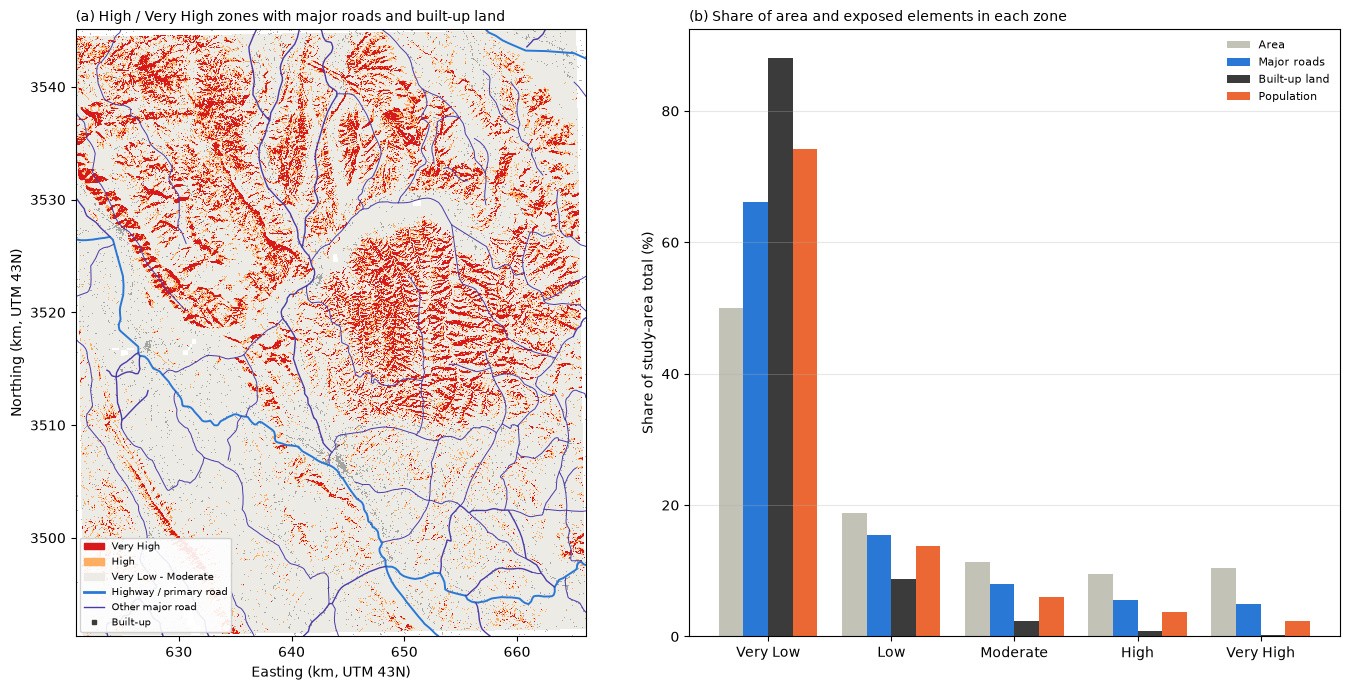

Saved to Results/: risk_exposure_by_zone.csv, risk_by_district.csv, priority_road_stretches.csv, fig_risk_exposure.png


In [40]:
# Cell 17 - Spatial risk framework: roads, built-up land and people in each zone
# Needs Cells 1-2 and the files saved by Cells 14 and 15
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from pathlib import Path
from pyproj import Transformer
from shapely.geometry import shape, LineString
from shapely.ops import transform as shp_transform
import rasterio
from rasterio.features import rasterize

RESULTS_DIR = Path("Results")
CLASS_NAMES = ['Very Low', 'Low', 'Moderate', 'High', 'Very High']
ROAD_TYPES = {1: 'Highway', 2: 'Primary', 3: 'Secondary', 4: 'Tertiary', 5: 'Local'}
STEP_M = 15  # sample roads every 15 m
TILE = 512

with rasterio.open(RESULTS_DIR / "susceptibility_zones.tif") as src:
    zones = src.read(1)  # 0 = no data, 1..5 = zones
    tf, crs_utm = src.transform, src.crs.to_string()
H, W = zones.shape
PIXEL = tf.a
px_km2 = PIXEL * PIXEL / 1e6
to_utm = Transformer.from_crs("EPSG:4326", crs_utm, always_xy=True)
to_ll = Transformer.from_crs(crs_utm, "EPSG:4326", always_xy=True)

def line_parts(g):
    # turn LineString / MultiLineString / LinearRing into plain lines
    if g is None or g.is_empty:
        return []
    if g.geom_type in ('LineString', 'LinearRing'):
        return [LineString(g.coords)]
    if g.geom_type == 'Polygon':
        return [LineString(g.exterior.coords)]
    return [p for sub in getattr(g, 'geoms', []) for p in line_parts(sub)]

def zone_at(x, y):
    col = np.floor((np.asarray(x) - tf.c) / PIXEL).astype(int)
    row = np.floor((tf.f - np.asarray(y)) / PIXEL).astype(int)
    ok = (row >= 0) & (row < H) & (col >= 0) & (col < W)
    z = np.zeros(len(col), dtype=int)
    z[ok] = zones[row[ok], col[ok]]
    return z

# roads
roads_fc = (ee.FeatureCollection('projects/sat-io/open-datasets/GRIP4/South-East-Asia')
            .merge(ee.FeatureCollection('projects/sat-io/open-datasets/GRIP4/Middle-East-Central-Asia'))
            .filterBounds(AOI))
roads = roads_fc.select(['GP_RTP']).getInfo()['features']
road_rows, stretches = [], []
for f in roads:
    line = shp_transform(lambda x, y, z=None: to_utm.transform(x, y), shape(f['geometry']))
    rtype = ROAD_TYPES.get(int(f['properties'].get('GP_RTP') or 5), 'Local')
    for part in line_parts(line):
        d = np.arange(STEP_M / 2, part.length, STEP_M)
        if len(d) == 0:
            continue
        pts = [part.interpolate(v) for v in d]
        xs, ys = np.array([p.x for p in pts]), np.array([p.y for p in pts])
        z = zone_at(xs, ys)
        for zz in range(1, 6):
            road_rows.append({'zone': zz, 'type': rtype, 'km': (z == zz).sum() * STEP_M / 1000})
        # continuous runs through High / Very High
        hot = z >= 4
        edges = np.flatnonzero(np.diff(np.r_[0, hot.astype(int), 0]))
        for a, b in zip(edges[::2], edges[1::2]):
            length_m = (b - a) * STEP_M
            if length_m >= 300:
                mid = (a + b) // 2
                lon_m, lat_m = to_ll.transform(xs[mid], ys[mid])
                stretches.append({'road_type': rtype, 'length_m': length_m,
                                  'share_very_high_%': 100 * (z[a:b] == 5).mean(),
                                  'mid_lat': round(lat_m, 5), 'mid_lon': round(lon_m, 5)})
if not road_rows:
    road_rows = [{'zone': 1, 'type': 'Highway', 'km': 0.0}]
road_tab = pd.DataFrame(road_rows).groupby(['zone', 'type']).km.sum().unstack(fill_value=0)
print(f"GRIP4 road features in the study area: {len(roads)}; "
      f"total length inside the map: {road_tab.values.sum():.1f} km")

# built-up land and population on the same 30 m grid
built = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').eq(50)
ghs_pop = ee.Image('JRC/GHSL/P2023A/GHS_POP/2020').select('population_count')
expo_img = (built.unmask(0).rename('built').toFloat()
            .addBands(ghs_pop.multiply(PIXEL * PIXEL / 10000.0).unmask(0)  # people per 30 m pixel
                      .rename('pop').toFloat()))
built_arr = np.zeros((H, W), dtype=np.float32)
pop_arr = np.zeros((H, W), dtype=np.float32)
t0 = time.time()
tiles = [(r, c) for r in range(0, H, TILE) for c in range(0, W, TILE)]
for k, (r, c) in enumerate(tiles, 1):
    h, w = min(TILE, H - r), min(TILE, W - c)
    grid = {'dimensions': {'width': w, 'height': h},
            'affineTransform': {'scaleX': PIXEL, 'shearX': 0, 'translateX': tf.c + c * PIXEL,
                                'shearY': 0, 'scaleY': -PIXEL, 'translateY': tf.f - r * PIXEL},
            'crsCode': crs_utm}
    for attempt in range(3):
        try:
            arr = ee.data.computePixels({'expression': expo_img, 'fileFormat': 'NUMPY_NDARRAY',
                                         'grid': grid})
            break
        except ee.EEException as e:
            if attempt == 2:
                raise
            print(f"   tile {k}: {str(e)[:60]} - retrying")
            time.sleep(5)
    built_arr[r:r + h, c:c + w] = arr['built']
    pop_arr[r:r + h, c:c + w] = arr['pop']
    print(f"[{(time.time() - t0) / 60:4.1f} min] tile {k}/{len(tiles)}")

# exposure table by zone
rows = []
for z, name in enumerate(CLASS_NAMES, 1):
    m = zones == z
    rows.append({'Zone': name, 'Area_km2': m.sum() * px_km2,
                 'Road_km': road_tab.loc[z].sum() if z in road_tab.index else 0.0,
                 'Built_up_km2': built_arr[m].sum() * px_km2,
                 'Population': pop_arr[m].sum()})
risk = pd.DataFrame(rows)
for col in ['Area_km2', 'Road_km', 'Built_up_km2', 'Population']:
    risk[col.split('_')[0] + '_%'] = 100 * risk[col] / risk[col].sum()
risk.to_csv(RESULTS_DIR / "risk_exposure_by_zone.csv", index=False)
print("\nExposure by susceptibility zone:")
display(risk.round(1))
road_tab.index = [CLASS_NAMES[i - 1] for i in road_tab.index]
print("\nRoad length (km) by zone and road type:")
display(road_tab.round(1))

hv = risk.iloc[3:5].sum(numeric_only=True)
print(f"\nHigh + Very High zones: {hv['Area_%']:.1f}% of the area, {hv['Road_%']:.1f}% of major "
      f"roads ({hv['Road_km']:.1f} km), {hv['Built_%']:.1f}% of built-up land "
      f"({hv['Built_up_km2']:.2f} km2) and {hv['Population_%']:.1f}% of the population "
      f"(~{hv['Population']:,.0f} people)")

# districts
with open(RESULTS_DIR / "hp_districts.geojson") as fh:
    dist_feats = json.load(fh)['features']
shapes, names = [], []
for i, f in enumerate(dist_feats, 1):
    g = shp_transform(lambda x, y, z=None: to_utm.transform(x, y), shape(f['geometry']))
    shapes.append((g, i)); names.append(f['properties']['district'])
dist_r = rasterize(shapes, out_shape=(H, W), transform=tf, fill=0, dtype='int32')
d_rows = []
for i, n in enumerate(names, 1):
    m = (dist_r == i) & (zones > 0)
    if m.sum() == 0:
        continue
    d_rows.append({'District': n, 'Area_in_box_km2': m.sum() * px_km2,
                   'High_VeryHigh_km2': (m & (zones >= 4)).sum() * px_km2,
                   'High_VeryHigh_%': 100 * (m & (zones >= 4)).sum() / m.sum(),
                   'VeryHigh_%': 100 * (m & (zones == 5)).sum() / m.sum(),
                   'People_in_High_VeryHigh': pop_arr[m & (zones >= 4)].sum()})
dist_tab = pd.DataFrame(d_rows).sort_values('Area_in_box_km2', ascending=False)
dist_tab.to_csv(RESULTS_DIR / "risk_by_district.csv", index=False)
print("\nBy district (only the part inside the study area):")
display(dist_tab.round(1))

stretch_tab = pd.DataFrame(stretches)
if len(stretch_tab):
    stretch_tab = stretch_tab.sort_values('length_m', ascending=False).reset_index(drop=True)
    stretch_tab.to_csv(RESULTS_DIR / "priority_road_stretches.csv", index=False)
    print(f"\nRoad stretches of 300 m or more running through High / Very High ground: "
          f"{len(stretch_tab)} (longest 15 below, all in Results/priority_road_stretches.csv)")
    display(stretch_tab.head(15).round({'share_very_high_%': 1}))

# figure
fig, (axm, axb) = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [1, 1.05]})
base = np.select([zones == 5, zones == 4], [2.0, 1.0], 0.0)  # 0 other, 1 High, 2 Very High
base[zones == 0] = np.nan
extent_km = [tf.c / 1000, (tf.c + W * PIXEL) / 1000, (tf.f - H * PIXEL) / 1000, tf.f / 1000]
axm.imshow(base, cmap=ListedColormap(['#ecebe6', '#fdae61', '#d7191c']), vmin=-0.5, vmax=2.5,
           extent=extent_km, interpolation='nearest')
by, bx = np.nonzero(built_arr[::3, ::3] > 0)  # every 3rd pixel keeps the plot light
axm.scatter((tf.c + (bx * 3 + 0.5) * PIXEL) / 1000, (tf.f - (by * 3 + 0.5) * PIXEL) / 1000,
            s=0.15, c='#3b3b3b', linewidths=0)
road_style = {'Highway': ('#2a78d6', 2.0), 'Primary': ('#2a78d6', 1.4),
              'Secondary': ('#4a3aa7', 1.0), 'Tertiary': ('#4a3aa7', 0.7), 'Local': ('#4a3aa7', 0.5)}
for f in roads:
    line = shp_transform(lambda x, y, z=None: to_utm.transform(x, y), shape(f['geometry']))
    rtype = ROAD_TYPES.get(int(f['properties'].get('GP_RTP') or 5), 'Local')
    col, lw = road_style[rtype]
    for part in line_parts(line):
        x, y = part.xy
        axm.plot(np.array(x) / 1000, np.array(y) / 1000, color=col, lw=lw)
axm.set_xlim(extent_km[0], extent_km[1]); axm.set_ylim(extent_km[2], extent_km[3])
axm.set_xlabel('Easting (km, UTM 43N)'); axm.set_ylabel('Northing (km, UTM 43N)')
axm.set_title('(a) High / Very High zones with major roads and built-up land', fontsize=10, loc='left')
axm.legend(handles=[Patch(color='#d7191c', label='Very High'), Patch(color='#fdae61', label='High'),
                    Patch(color='#ecebe6', label='Very Low - Moderate'),
                    plt.Line2D([], [], color='#2a78d6', lw=2, label='Highway / primary road'),
                    plt.Line2D([], [], color='#4a3aa7', lw=1, label='Other major road'),
                    plt.Line2D([], [], marker='s', ls='', color='#3b3b3b', ms=3, label='Built-up')],
           loc='lower left', fontsize=7, framealpha=0.9)

x = np.arange(len(CLASS_NAMES))
series = [('Area_%', 'Area', '#c3c2b7'), ('Road_%', 'Major roads', '#2a78d6'),
          ('Built_%', 'Built-up land', '#3b3b3b'), ('Population_%', 'Population', '#eb6834')]
bw = 0.2
for i, (col, lab, colr) in enumerate(series):
    axb.bar(x + (i - 1.5) * bw, risk[col], bw, color=colr, label=lab)
axb.set_xticks(x, CLASS_NAMES)
axb.set_ylabel('Share of study-area total (%)')
axb.set_title('(b) Share of area and exposed elements in each zone', fontsize=10, loc='left')
axb.legend(frameon=False, fontsize=8)
axb.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_risk_exposure.png", dpi=600)
plt.show()
print("Saved to Results/: risk_exposure_by_zone.csv, risk_by_district.csv, "
      "priority_road_stretches.csv, fig_risk_exposure.png")

**Result:**
- The High and Very High zones (19.9% of the area) contain 10.5% of the major roads (71.9 km), 1.0% of the built-up land (0.46 km²) and about 57,000 people (6.0%).
- Most people and buildings are in the Very Low zone (74% and 88%), on terraces and valley floors. Roads are more exposed because they have to cross the hills.
- By district, the Kangra part has the most High and Very High ground (28.2%), then Mandi (22.8%) and Hamirpur (13.7%).
- 40 road stretches of 300 m or more (17.5 km in total) run through High or Very High ground, 37 of them tertiary roads. These are the first candidates for slope protection and drainage work (full list in `Results/priority_road_stretches.csv`).
- Figure: (a) High and Very High zones with roads and built-up land; (b) each zone's share of area, roads, built-up land and population.